# 02 · Tracking and dunes

Handoff §3 Steps 2, 2b, 3 and 5 for **one site**, chosen by `DUNESIGHT_SITE` (boxes in `pipeline/sites.json`). Everything site-specific comes from config: the box, CRS, WRS-2 path/row and HLS tile (`sites.json`), the confirmed scene list (`pipeline/site_config/<site>/scenes_confirmed.json`) and optional hand-drawn exclusion polygons (`pipeline/site_config/<site>/manual_masks.geojson`). Method parameters are in one dictionary below and can be overridden per site with a `notebook02` entry in `sites.json`.

**What it measures and how (plain language)**
1. **Imagery.** Landsat panchromatic band 8 (15 m) for the confirmed November scenes, cut to the box plus a margin on the Landsat pan pixel grid itself (no resampling), with the `QA_PIXEL` cloud/shadow mask. A few extra Landsat 8/9 scenes from October and December of the same winters are added **only** to measure how a change of sun elevation fools the matcher (they are not used for velocities).
2. **Matching.** The image is cut into 32 × 32-pixel windows (480 m), every 8 pixels (120 m). Each window in one year is matched to the same place in another year by phase correlation, with sub-pixel refinement. The matcher is first tested on images shifted by known amounts.
3. **Many pairs, not one.** Every pair of the 2013-2025 Landsat 8/9 scenes is matched (1 to 12 years apart). For each window the pairs are combined into one position per year (a network: A→B plus B→C must equal A→C), and the velocity is the slope of position against time. If motion is real, displacement grows in proportion to the time between images; if a match jumped to the neighbouring dune, it fails to close with the other pairs and is thrown out.
4. **Stable ground and noise.** Surfaces that do not move (established farms, roads, buildings that look the same in every year) give the offset between images, which is removed, and the scatter of their apparent "velocities" is the noise. The detection limit comes from that scatter, and windows slower than it are reported as **below detection limit**.
5. **Checks.** Illumination (pairs a few weeks apart with very different sun elevation), the Landsat 7 2000/2001 scenes as a long-baseline check, an independent satellite (Sentinel-2 via NASA HLS S30) and the same Landsat via HLS L30, and the wind direction from notebook 01.
6. **Dunes.** NASADEM (February 2000) is tested for whether it resolves the dunes; dunes are outlined from it only where it does, and each outline gets the motion measured inside it.

Outputs: `public/data/<site>/dunes.geojson`, `dunes_2000.geojson`, `vectors.geojson`, the site index `public/data/sites.json`, and in `pipeline/outputs/<site>/` a QC summary (`02_qc_summary.json`), tables and figures (`02_*.png`).

In [1]:
# WHAT THIS DOES: imports, picks the site from DUNESIGHT_SITE, sets folders, loads .env (secrets are never printed)
# and defines the method parameters (defaults below, optionally overridden per site in sites.json "notebook02").
import json, os, sys, time, math, hashlib, datetime as dt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

PIPELINE = next(p for p in [Path.cwd(), Path.cwd() / "pipeline", Path.cwd().parent, Path.cwd().parent.parent]
                if (p / "dunesight").is_dir())
sys.path.insert(0, str(PIPELINE))

import numpy as np
import pandas as pd
import requests
import warnings
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from dotenv import load_dotenv
from pyproj import Transformer

from dunesight import config, site_index, wind, landsat, rasters, masks, tracking as tk, network as nw, motion, dunes as dn

# windows that contain masked (NaN) pixels produce expected "empty slice" warnings; they are handled explicitly
for msg in ("Mean of empty slice", "All-NaN slice", "Degrees of freedom", "invalid value encountered", "divide by zero"):
    warnings.filterwarnings("ignore", message=f".*{msg}.*")

SITE = config.get_site()
SID = SITE["id"]
OUT = config.outputs_dir(SID); OUT.mkdir(parents=True, exist_ok=True)
RAW = config.raw_dir(SID); RAW.mkdir(parents=True, exist_ok=True)
PUB = config.public_dir(SID); PUB.mkdir(parents=True, exist_ok=True)
SITE_CFG = config.PIPELINE / "site_config" / SID
load_dotenv(config.ROOT / ".env")
plt.rcParams.update({"figure.dpi": 60, "savefig.dpi": 90, "font.size": 9})

P = dict(
    grid_margin_m=1500,      # extra ground around the box so guided/shifted windows stay inside the image
    win=32, step=8,          # window (px) and spacing (px) on the 15 m grid: 480 m windows every 120 m
    margin_px=24,            # windows keep this far from the image edge
    upsample=100,            # sub-pixel resolution 1/100 px
    null_pctl=99.0,          # match-quality threshold = this percentile of the peak height for unrelated windows
    max_disp_px=4.0,         # largest displacement accepted from an unguided match (synthetic tests: reliable to ~3-4 px)
    stable_min_frac=0.75,    # a stable-ground window is >= 75 % covered by the automatic non-dune layers ...
    stable_min_med_peak=0.5, # ... looks alike in every OLI pair (median peak >= 0.5) ...
    stable_min_valid=0.9,    # ... and is valid in >= 90 % of OLI pairs
    dune_max_nondune=0.25,   # a dune window has <= 25 % of its area in the non-dune mask
    dune_min_valid=0.6,      # and is valid in >= 60 % of OLI pairs
    aux_days=40,             # illumination-test scenes: within +-40 days of a confirmed OLI scene
    ndvi_margin=0.07,        # vegetated = max NDVI > box median + 0.07
    vector_thin=2,           # vectors.geojson keeps every 2nd window in each direction (240 m spacing)
    dem_smooth_px=1.0, dem_k_sigma=3.0, dem_corr_px=9, dem_min_px=4,
    dem_base_radius_m=300,   # local base = DEM opened with a 300 m disk (wider than the dunes)
    hls_win=24, hls_step=4,  # HLS 30 m: 720 m windows every 120 m
    seed=20261114,
)
P.update(SITE.get("notebook02", {}))
RES = 15.0
print(f"site: {SID} ({SITE['name']}); box W,S,E,N = {config.bbox_list(SITE)}; EPSG:{SITE['epsg']}; WRS-2 {SITE['wrs_path']}/{SITE['wrs_row']:03d}; HLS tile {SITE['hls_tile']}")
print("credentials present:", {k: bool(os.getenv(k)) for k in ("EE_PROJECT", "EARTHDATA_USERNAME", "EARTHDATA_PASSWORD")})
print("parameters:", P)
QC = {"site": SID, "generated_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"), "parameters": P}

site: seih_al_hama (Seih Al Hama, SW of Al Ain); box W,S,E,N = [55.475, 24.015, 55.575, 24.105]; EPSG:32640; WRS-2 160/043; HLS tile T40QCM
credentials present: {'EE_PROJECT': True, 'EARTHDATA_USERNAME': True, 'EARTHDATA_PASSWORD': True}
parameters: {'grid_margin_m': 1500, 'win': 32, 'step': 8, 'margin_px': 24, 'upsample': 100, 'null_pctl': 99.0, 'max_disp_px': 4.0, 'stable_min_frac': 0.75, 'stable_min_med_peak': 0.5, 'stable_min_valid': 0.9, 'dune_max_nondune': 0.25, 'dune_min_valid': 0.6, 'aux_days': 40, 'ndvi_margin': 0.07, 'vector_thin': 2, 'dem_smooth_px': 1.0, 'dem_k_sigma': 3.0, 'dem_corr_px': 9, 'dem_min_px': 4, 'dem_base_radius_m': 300, 'hls_win': 24, 'hls_step': 4, 'seed': 20261114}


## 1 · The confirmed scene list

The user confirmed notebook 01's November list on 2026-11-14. That confirmation lives in `pipeline/site_config/<site>/scenes_confirmed.json` (written once by hand, never regenerated). The next cell refuses to run if that file is missing or no longer matches notebook 01's proposal, so a re-run of notebook 01 cannot silently change the data under the velocities.

In [2]:
# WHAT THIS DOES: reads the confirmed scene list and checks it against notebook 01's scenes_selected.json.
conf_path = SITE_CFG / "scenes_confirmed.json"
if not conf_path.exists():
    raise SystemExit(f"No confirmed scene list for {SID}: {conf_path.relative_to(config.ROOT)} is missing. "
                     "Run notebook 01, have the user confirm the list, then record it there.")
CONF = json.loads(conf_path.read_text())
sel = json.loads((OUT / "scenes_selected.json").read_text())
proposal = sel["recommended"] if sel["recommended_month"] == CONF["month"] else sel["alternative"]
assert [s["scene_id"] for s in proposal] == [s["scene_id"] for s in CONF["scenes"]], "confirmed list differs from notebook 01's proposal"
print(f"confirmed on {CONF['confirmed_on']} by {CONF['confirmed_by']}: {len(CONF['scenes'])} {CONF['month']} scenes; matches notebook 01's proposal")
print(pd.DataFrame(CONF["scenes"])[["date", "scene_id", "sensor", "sun_elevation_deg", "sun_azimuth_deg"]].to_string(index=False))

confirmed on 2026-11-14 by Sultan (project owner): 14 November scenes; matches notebook 01's proposal
      date                                 scene_id             sensor  sun_elevation_deg  sun_azimuth_deg
2000-11-27 LE07_L1TP_160043_20001127_20200918_02_T1  Landsat 7 ETM+ B8              39.30           152.54
2001-11-30 LE07_L1TP_160043_20011130_20200917_02_T1  Landsat 7 ETM+ B8              38.57           152.05
2013-11-07 LC08_L1TP_160043_20131107_20200912_02_T1   Landsat 8 OLI B8              45.25           154.17
2014-11-10 LC08_L1TP_160043_20141110_20200910_02_T1   Landsat 8 OLI B8              44.36           154.11
2015-11-13 LC08_L1TP_160043_20151113_20200908_02_T1   Landsat 8 OLI B8              43.63           154.43
2016-11-15 LC08_L1TP_160043_20161115_20200905_02_T1   Landsat 8 OLI B8              42.95           154.76
2017-11-02 LC08_L1TP_160043_20171102_20200902_02_T1   Landsat 8 OLI B8              46.48           152.83
2019-11-08 LC08_L1TP_160043_20191108_20200

## 2 · Downloads (cached in `pipeline/raw/<site>/`)

**Grid.** One north-up grid in the site's UTM zone, 15 m pixels, covering the box plus a 1.5 km margin. Its pixel corners are placed at the same phase (7.5 m mod 15 m) as the Landsat Collection 2 pan grid, so Earth Engine copies band 8 pixels one-to-one, without interpolation; the next cell checks that phase on every scene. `QA_PIXEL` (30 m) is copied by nearest neighbour onto the same grid (each QA pixel covers 2 × 2 pan pixels, offset by half a pan pixel; the mask is dilated by one pixel to cover that).

**Extra scenes for the illumination test.** For each confirmed Landsat 8/9 scene, the clean scenes (notebook 01's checks: box fully covered, ≤ 1 % cloud/shadow in the box, no haze flag, valid B8) within ±40 days with the highest and the lowest sun elevation. Within a few weeks the dunes cannot move more than a fraction of a metre, but the sun elevation changes by up to ~12°, so any apparent motion between such scenes is mostly an illumination artefact.

In [3]:
# WHAT THIS DOES: builds the grid, picks the illumination-test scenes, and downloads B8 + QA_PIXEL for every scene
# (confirmed and illumination-test) from Earth Engine on that grid, with per-scene metadata. Cached.
ee = landsat.ee_init(config.ROOT)
GRID = rasters.site_grid(SITE["bbox"], SITE["epsg"], margin_m=P["grid_margin_m"], res=RES, phase=7.5)
INBOX = rasters.box_mask(GRID, SITE["bbox"])
print("grid:", GRID, f"-> {GRID.width * RES / 1000:.2f} x {GRID.height * RES / 1000:.2f} km")

cand = pd.read_csv(OUT / "landsat_candidates.csv", parse_dates=["date"])
clean = cand[(cand.covers_box == True) & (cand.cloud_ok == True) & (cand.haze_ok == True) & (cand.b8_ok == True)]
aux = []
for s in CONF["scenes"]:
    if "Landsat 7" in s["sensor"]:
        continue
    d = pd.Timestamp(s["date"])
    c = clean[((clean.date - d).dt.days.abs() <= P["aux_days"]) & (clean.scene_id != s["scene_id"]) & clean.collection.str.contains("LC0")]
    if len(c):
        for r in (c.loc[c.sun_elevation.idxmax()], c.loc[c.sun_elevation.idxmin()]):
            aux.append(dict(scene_id=r.scene_id, ee_asset=f"{r.collection}/{r.ee_id}", partner=s["scene_id"]))
aux = pd.DataFrame(aux).drop_duplicates("scene_id")
jobs = [dict(scene_id=s["scene_id"], ee_asset=s["ee_asset"], role="confirmed") for s in CONF["scenes"]]
jobs += [dict(scene_id=r.scene_id, ee_asset=r.ee_asset, role="illumination_test") for r in aux.itertuples()]
print(f"{len(CONF['scenes'])} confirmed + {len(aux)} illumination-test scenes")

KEYS = ["LANDSAT_PRODUCT_ID", "DATE_ACQUIRED", "SCENE_CENTER_TIME", "SPACECRAFT_ID", "SENSOR_ID", "SUN_ELEVATION", "SUN_AZIMUTH",
        "CLOUD_COVER", "GEOMETRIC_RMSE_MODEL", "GEOMETRIC_RMSE_MODEL_X", "GEOMETRIC_RMSE_MODEL_Y", "GROUND_CONTROL_POINTS_MODEL",
        "REFLECTANCE_MULT_BAND_8", "REFLECTANCE_ADD_BAND_8", "PROCESSING_SOFTWARE_VERSION", "COLLECTION_CATEGORY", "WRS_PATH", "WRS_ROW"]
def fetch_scene(j):
    p = RAW / "landsat_b8" / f"{j['scene_id']}.tif"
    meta_p = p.with_suffix(".json")
    if p.exists() and meta_p.exists():
        return
    im = ee.Image(j["ee_asset"])
    md = im.toDictionary(KEYS).getInfo()
    md["native_b8_transform"] = im.select("B8").projection().getInfo()["transform"]
    md["ee_asset"] = j["ee_asset"]
    rasters.ee_download(im, GRID, p, ["B8", "QA_PIXEL"], meta=md)
with ThreadPoolExecutor(6) as ex:
    list(ex.map(fetch_scene, jobs))

rows = []
for j in jobs:
    m = json.loads((RAW / "landsat_b8" / f"{j['scene_id']}.json").read_text())
    ts = pd.Timestamp(m["DATE_ACQUIRED"] + " " + m["SCENE_CENTER_TIME"][:8])
    tr = m["native_b8_transform"]
    rows.append(dict(scene_id=m["LANDSAT_PRODUCT_ID"], role=j["role"], date=m["DATE_ACQUIRED"], time_utc=m["SCENE_CENTER_TIME"][:8],
                     t=ts.year + (ts.day_of_year - 1 + (ts.hour + ts.minute / 60) / 24) / (366 if ts.is_leap_year else 365),
                     spacecraft=m["SPACECRAFT_ID"], sensor="ETM+" if m["SPACECRAFT_ID"] == "LANDSAT_7" else "OLI",
                     sun_el=m["SUN_ELEVATION"], sun_az=m["SUN_AZIMUTH"], cloud_scene=m["CLOUD_COVER"],
                     geometric_rmse_model_m=m["GEOMETRIC_RMSE_MODEL"], gcp_model=m["GROUND_CONTROL_POINTS_MODEL"],
                     b8_grid_phase_ok=(abs((tr[2] - GRID.x0) % RES) < 1e-6) and (abs((tr[5] - GRID.y0) % RES) < 1e-6) and tr[0] == RES,
                     ee_asset=m["ee_asset"]))
SC = pd.DataFrame(rows).sort_values("t").reset_index(drop=True)
assert SC.b8_grid_phase_ok.all(), "a scene's B8 grid is not on the download grid phase (would be resampled)"
print("every scene's native B8 grid has the download grid's phase -> pixels copied without resampling")
print(f"Collection 2 GEOMETRIC_RMSE_MODEL across scenes: {SC.geometric_rmse_model_m.min():.1f}-{SC.geometric_rmse_model_m.max():.1f} m "
      "(the scene's model fit to ground control; the residual offset between two scenes is measured below on stable ground)")
SC.round(4).to_csv(OUT / "02_scenes_downloaded.csv", index=False)
print(SC[["date", "role", "spacecraft", "sun_el", "sun_az", "geometric_rmse_model_m"]].to_string())

grid: Grid(crs='EPSG:32640', x0=343387.5, y0=2668207.5, res=15.0, width=886, height=874) -> 13.29 x 13.11 km
14 confirmed + 23 illumination-test scenes
every scene's native B8 grid has the download grid's phase -> pixels copied without resampling
Collection 2 GEOMETRIC_RMSE_MODEL across scenes: 3.5-8.0 m (the scene's model fit to ground control; the residual offset between two scenes is measured below on stable ground)
          date               role spacecraft     sun_el      sun_az  geometric_rmse_model_m
0   2000-11-27          confirmed  LANDSAT_7  39.295403  152.542519                   4.972
1   2001-11-30          confirmed  LANDSAT_7  38.574117  152.054038                   4.835
2   2013-11-07          confirmed  LANDSAT_8  45.245041  154.173478                   5.392
3   2013-12-09  illumination_test  LANDSAT_8  38.469195  155.224325                   5.772
4   2014-10-09  illumination_test  LANDSAT_8  53.581795  145.194385                   4.208
5   2014-11-10          c

In [4]:
# WHAT THIS DOES: downloads the mask layers on the same grid: max/median NDVI over the confirmed scenes (Landsat TOA,
# 30 m), ESA WorldCover v200 (2021), OpenStreetMap features (Overpass), and NASADEM on a 30 m grid aligned with it.
MASK_DIR = RAW / "masks"; MASK_DIR.mkdir(exist_ok=True)
def ndvi(asset):
    im = ee.Image(asset)
    red, nir = ("B3", "B4") if "LE07" in asset else ("B4", "B5")
    toa = lambda b: im.select(b).multiply(ee.Number(im.get(f"REFLECTANCE_MULT_BAND_{b[1:]}"))).add(ee.Number(im.get(f"REFLECTANCE_ADD_BAND_{b[1:]}")))
    r, n = toa(red), toa(nir)
    return n.subtract(r).divide(n.add(r))
nd_coll = ee.ImageCollection([ndvi(s["ee_asset"]) for s in CONF["scenes"]])
rasters.ee_download(ee.Image.cat([nd_coll.max(), nd_coll.median()]).rename(["ndvi_max", "ndvi_med"]).toFloat(), GRID,
                    MASK_DIR / "landsat_ndvi_nov.tif", ["ndvi_max", "ndvi_med"])
rasters.ee_download(ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").toUint8(), GRID, MASK_DIR / "worldcover_v200_2021.tif", ["Map"])

osm_path = MASK_DIR / "osm_features.json"
if not osm_path.exists():
    b, m = SITE["bbox"], 0.015
    bb = f"{b['south'] - m},{b['west'] - m},{b['north'] + m},{b['east'] + m}"
    q = (f'[out:json][timeout:180];( way["highway"]({bb}); nwr["building"]({bb}); nwr["landuse"]({bb}); nwr["leisure"]({bb});'
         f' nwr["sport"]({bb}); nwr["man_made"]({bb}); nwr["amenity"]({bb}); nwr["barrier"]({bb}); ); out tags geom;')
    r = requests.post("https://overpass-api.de/api/interpreter", data={"data": q},
                      headers={"User-Agent": "DuneSight-pipeline/0.1 (open-source research)"}, timeout=300)
    r.raise_for_status(); osm_path.write_text(r.text)
OSM = json.loads(osm_path.read_text())
print("OSM snapshot:", OSM["osm3s"]["timestamp_osm_base"], "elements:", len(OSM["elements"]))

G30 = GRID.coarsen(2)   # 30 m grid, every 2 x 2 block of the 15 m grid
dem_img = ee.Image("NASA/NASADEM_HGT/001")
rasters.ee_download(dem_img.select(["elevation"]).toFloat().resample("bilinear"), G30, RAW / "dem" / "nasadem_elevation_30m_bilinear.tif", ["elevation"])
print("NASADEM native projection:", dem_img.projection().getInfo()["transform"][:1], "deg (1 arc-second); resampled bilinearly to the 30 m UTM grid")

OSM snapshot: 2026-11-15T02:19:27Z elements: 766


NASADEM native projection: [0.0002777777777777778] deg (1 arc-second); resampled bilinearly to the 30 m UTM grid


## 3 · Images and masks

**Non-dune mask** (excluded from dune statistics), all on the 15 m grid:
- **vegetated**: maximum NDVI over the 14 confirmed scenes more than 0.07 above the box median (bare red sand already has a top-of-atmosphere NDVI near 0.15, so a fixed absolute threshold would not carry over to other sites);
- **ESA WorldCover 2021**: tree cover, cropland, built-up, water;
- **OpenStreetMap**: roads buffered by a half-width that depends on the road class, buildings and land-use areas;
- **hand-drawn polygons** (`site_config/<site>/manual_masks.geojson`) for human change that is obvious in the images but missed by the layers above (each polygon carries its reason).

**Stable ground** (co-registration and noise) comes only from windows ≥ 75 % covered by the *automatic* layers, outside the hand-drawn change areas, that look alike in every Landsat 8/9 pair (median match quality ≥ 0.5, valid in ≥ 90 % of pairs). That last condition removes surfaces that changed (new buildings, sand on a road, cleared plots) without looking at their displacement, so the selection cannot bias the offset.

in-box QA-masked pixels (%): {'2000-11-27': 0.003, '2001-11-30': 0.0, '2013-11-07': 0.0, '2013-12-09': 0.011, '2014-10-09': 0.0, '2014-11-10': 0.0, '2014-11-26': 0.026, '2015-10-12': 0.0, '2015-11-13': 0.01, '2015-12-15': 0.324, '2016-10-14': 0.004, '2016-11-15': 0.0, '2016-12-01': 0.005, '2017-10-01': 0.0, '2017-11-02': 0.0, '2017-12-04': 0.027, '2019-10-07': 0.0, '2019-11-08': 0.0, '2019-11-24': 0.004, '2020-10-09': 0.009, '2020-11-10': 0.0, '2020-12-12': 0.014, '2021-10-12': 0.0, '2021-11-13': 0.006, '2021-12-23': 0.021, '2022-09-29': 0.004, '2022-11-08': 0.0, '2022-12-18': 0.3, '2023-10-10': 0.0, '2023-11-19': 0.0, '2023-12-29': 0.02, '2024-10-04': 0.0, '2024-11-13': 0.0, '2024-12-23': 0.045, '2025-09-29': 0.0, '2025-11-08': 0.0, '2025-12-10': 0.869}
{
 "vegetated_ndvi_threshold": 0.222,
 "inbox_pct_vegetated": 7.7,
 "inbox_pct_worldcover": 4.4,
 "inbox_pct_osm": 18.8,
 "inbox_pct_manual": 43.3,
 "inbox_pct_nondune_total": 57.7,
 "osm_feature_counts": {
  "highway": 696,
  "landuse

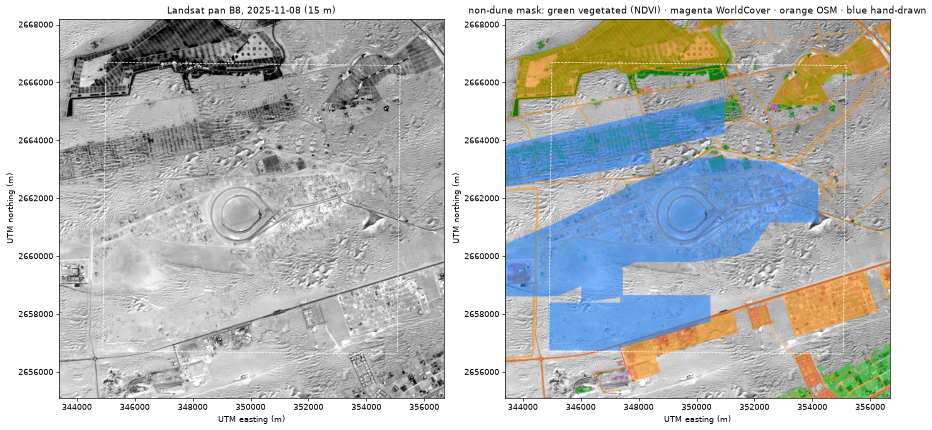

In [5]:
# WHAT THIS DOES: loads every scene (B8 with QA-masked pixels set to NaN), reports the in-box masked fraction,
# builds the mask layers and draws them over the latest confirmed image.
def load_b8(scene_id):
    a, _ = rasters.read(RAW / "landsat_b8" / f"{scene_id}.tif")
    b8 = a[0].astype(np.float32)
    bad = masks.qa_mask(a[1].astype(np.uint16), dilate_px=1) | (a[0] == 0)
    b8[bad] = np.nan
    return b8
IMGS = [load_b8(s) for s in SC.scene_id]
SC["inbox_masked_pct"] = [100 * np.isnan(im[INBOX]).mean() for im in IMGS]
print("in-box QA-masked pixels (%):", SC.set_index("date").inbox_masked_pct.round(3).to_dict())

ndv, _ = rasters.read(MASK_DIR / "landsat_ndvi_nov.tif")
wcv, _ = rasters.read(MASK_DIR / "worldcover_v200_2021.tif")
VEG, ndvi_thr = masks.vegetated_mask(ndv[0], INBOX, ndvi_margin=P["ndvi_margin"])
WCM = masks.worldcover_mask(wcv[0])
OSMM, osm_counts = masks.osm_mask(OSM, GRID)
MAN, man_info = masks.manual_mask(SITE_CFG / "manual_masks.geojson", GRID)
AUTO = VEG | WCM | OSMM
NONDUNE = AUTO | MAN
mask_stats = {"vegetated_ndvi_threshold": round(ndvi_thr, 3),
              **{f"inbox_pct_{k}": round(100 * float(v[INBOX].mean()), 1) for k, v in
                 dict(vegetated=VEG, worldcover=WCM, osm=OSMM, manual=MAN, nondune_total=NONDUNE).items()},
              "osm_feature_counts": osm_counts, "manual_polygons": [{"id": i, "reason": r} for i, r in man_info]}
QC["masks"] = mask_stats
print(json.dumps(mask_stats, indent=1))

LATEST = SC[SC.role == "confirmed"].index[-1]
def stretch(a):
    v = a[np.isfinite(a)]; lo, hi = np.percentile(v, [1, 99])
    return np.clip((a - lo) / (hi - lo), 0, 1)
def extent(g):
    return (g.x0, g.x0 + g.width * g.res, g.y0 - g.height * g.res, g.y0)
def box_outline(ax, g=GRID):
    tr = Transformer.from_crs("EPSG:4326", g.crs, always_xy=True)
    b = SITE["bbox"]; lon = [b["west"], b["east"], b["east"], b["west"], b["west"]]; lat = [b["south"], b["south"], b["north"], b["north"], b["south"]]
    x, y = tr.transform(np.interp(np.linspace(0, 4, 81), range(5), lon), np.interp(np.linspace(0, 4, 81), range(5), lat))
    ax.plot(x, y, "w--", lw=0.8)
base = stretch(np.nan_to_num(IMGS[LATEST], nan=np.nanmedian(IMGS[LATEST])))
fig, axes = plt.subplots(1, 2, figsize=(15, 7.6))
axes[0].imshow(base, cmap="gray", extent=extent(GRID)); axes[0].set_title(f"Landsat pan B8, {SC.date[LATEST]} (15 m)")
ov = np.dstack([base] * 3)
for m_, col in [(VEG, (0.1, 0.8, 0.1)), (WCM & ~VEG, (0.8, 0.2, 0.8)), (OSMM, (1.0, 0.55, 0.0)), (MAN, (0.1, 0.5, 1.0))]:
    ov[m_] = 0.45 * ov[m_] + 0.55 * np.array(col)
axes[1].imshow(ov, extent=extent(GRID))
axes[1].set_title("non-dune mask: green vegetated (NDVI) · magenta WorldCover · orange OSM · blue hand-drawn")
for a in axes:
    box_outline(a); a.set_xlabel("UTM easting (m)"); a.set_ylabel("UTM northing (m)"); a.ticklabel_format(style="plain")
plt.tight_layout(); plt.savefig(OUT / "02_masks.png"); plt.show()

## 4 · Testing the matcher before trusting it

Three tests on the real latest image, run on the same windows as the real analysis:
1. **Known shifts**: the image is shifted by sub-pixel and multi-pixel amounts (Fourier shift), once clean and once with noise (3 % of the mean), a contrast change (×0.7), a brightness offset (+30 %) and a gamma change, which together are harsher than the real sensor/illumination differences. The matcher should return the shift with no bias.
2. **Direction convention**: content moved 1 pixel east must give heading 90°, 1 pixel north heading 0°, south-east 135°. On this grid +row is south, so north = −row × 15 m; this is easy to get backwards, so it is tested.
3. **Quality threshold**: every window is matched against an *unrelated* window (40 pixels away). The peak heights of those false matches give the threshold: a match is accepted only if its peak is above the 99th percentile of the false-match peaks.

In [6]:
# WHAT THIS DOES: runs the known-shift tests and the direction-convention test on the latest confirmed image.
RR, CCm = tk.window_centres((GRID.height, GRID.width), P["win"], P["step"], margin=P["margin_px"])
NWX = RR.shape
rr, cc = RR.ravel(), CCm.ravel()
CIN = INBOX[rr, cc]
F_AUTO = tk.window_stat(AUTO, rr, cc, P["win"])
F_MAN = tk.window_stat(MAN, rr, cc, P["win"])
F_ND = tk.window_stat(NONDUNE, rr, cc, P["win"])
DUNE = CIN & (F_ND <= P["dune_max_nondune"])
DUNE_IDX = np.where(DUNE)[0]
DI = np.arange(DUNE_IDX.size)
NONDUNE_D = ndimage.binary_dilation(NONDUNE, iterations=1)
MAXNAN_D = min(0.5, P["dune_max_nondune"] + 0.15)   # dilated mask + QA may cover a little more than the window selection allowed
print(f"{rr.size} windows ({NWX[0]} x {NWX[1]}), {CIN.sum()} with centre inside the box, {DUNE.sum()} dune windows (<= {P['dune_max_nondune']:.0%} non-dune)")
ref = np.nan_to_num(IMGS[LATEST], nan=float(np.nanmedian(IMGS[LATEST]))).astype(float)
rng = np.random.default_rng(P["seed"])
syn = []
for dr_, dc_ in [(0, 0), (0.1, -0.2), (0.25, 0.4), (-0.5, 0.5), (1.3, -0.7), (3.0, 2.0), (-5.7, 4.2), (8.0, -8.0)]:
    for degraded in (False, True):
        B = tk.fourier_shift_image(ref, dr_, dc_)
        if degraded:
            B = np.clip(0.7 * B + 0.3 * ref.mean() + rng.normal(0, 0.03 * ref.mean(), B.shape), 1, None) ** 1.05
        o = tk.track_pair(ref, B, rr[CIN], cc[CIN], win=P["win"], upsample=P["upsample"])
        er, ec = o["d_row"] - dr_, o["d_col"] - dc_
        e = np.hypot(er, ec) * RES
        syn.append(dict(shift_row_px=dr_, shift_col_px=dc_, degraded=degraded, bias_row_px=round(float(np.nanmedian(er)), 3),
                        bias_col_px=round(float(np.nanmedian(ec)), 3), nmad_row_px=round(float(tk.nmad(er)), 3), nmad_col_px=round(float(tk.nmad(ec)), 3),
                        p95_error_m=round(float(np.nanpercentile(e, 95)), 2), pct_error_gt_1px=round(100 * float(np.nanmean(e > RES)), 1),
                        median_peak=round(float(np.nanmedian(o["peak"])), 2)))
# dune windows are matched with their non-dune pixels masked out (zero weight, feathered edges). The mask is fixed on
# the ground while the content moves, so test that the static mask edge does not pull the result toward zero:
part = DUNE_IDX[F_ND[DUNE_IDX] > 0.05]
refm = np.where(NONDUNE_D, np.nan, ref)
for dr_, dc_ in [(0.25, 0.4), (1.3, -0.7), (3.0, 2.0)]:
    for degraded in (False, True):
        B = tk.fourier_shift_image(ref, dr_, dc_)
        if degraded:
            B = np.clip(0.7 * B + 0.3 * ref.mean() + rng.normal(0, 0.03 * ref.mean(), B.shape), 1, None) ** 1.05
        B = np.where(NONDUNE_D, np.nan, B)
        o = tk.track_pair(refm, B, rr[part], cc[part], win=P["win"], upsample=P["upsample"], max_nan_frac=MAXNAN_D)
        er, ec = o["d_row"] - dr_, o["d_col"] - dc_
        e = np.hypot(er, ec) * RES
        syn.append(dict(shift_row_px=dr_, shift_col_px=dc_, degraded=degraded, masked=f"{part.size} partly masked dune windows",
                        bias_row_px=round(float(np.nanmedian(er)), 3), bias_col_px=round(float(np.nanmedian(ec)), 3),
                        nmad_row_px=round(float(tk.nmad(er)), 3), nmad_col_px=round(float(tk.nmad(ec)), 3),
                        p95_error_m=round(float(np.nanpercentile(e, 95)), 2), pct_error_gt_1px=round(100 * float(np.nanmean(e > RES)), 1),
                        median_peak=round(float(np.nanmedian(o["peak"])), 2)))
SYN = pd.DataFrame(syn)
SYN["masked"] = SYN["masked"].fillna("no")
print(SYN.to_string(index=False))
SYN.to_csv(OUT / "02_synthetic_tests.csv", index=False)

# direction convention: content moves +1 px east (col), +1 px north (row -1), and south-east
dirs = []
for name, (dr_, dc_), expect in [("east", (0, 1), 90.0), ("north", (-1, 0), 0.0), ("south-east", (1, 1), 135.0), ("west", (0, -1), 270.0)]:
    o = tk.track_pair(ref, tk.fourier_shift_image(ref, dr_, dc_), rr[CIN][:500], cc[CIN][:500], win=P["win"])
    e_, n_ = np.nanmedian(o["d_col"]) * RES, -np.nanmedian(o["d_row"]) * RES
    h = float(tk.heading_deg(e_, n_))
    dirs.append(dict(case=name, east_m=round(e_, 2), north_m=round(n_, 2), heading_deg=round(h, 1), expected=expect, ok=bool(wind.angle_diff(h, expect) < 1)))
print(pd.DataFrame(dirs).to_string(index=False))
assert all(d["ok"] for d in dirs), "heading convention test failed"
QC["synthetic_tests"] = {"table": syn, "direction_tests": dirs,
                         "summary": "clean shifts up to 8 px recovered with |bias| <= 0.1 px; with noise+contrast+brightness+gamma changes, "
                                    f"bias <= {SYN[SYN.degraded & (SYN.shift_row_px.abs() <= 3)][['bias_row_px', 'bias_col_px']].abs().max().max():.2f} px for shifts <= 3 px "
                                    f"and {SYN[SYN.degraded & (SYN.shift_row_px.abs() > 3)].pct_error_gt_1px.max():.0f} % failures for shifts > 3 px; "
                                    f"with non-dune pixels masked, bias <= {SYN[SYN.masked != 'no'][['bias_row_px', 'bias_col_px']].abs().max().max():.2f} px"}

10100 windows (100 x 101), 7035 with centre inside the box, 2417 dune windows (<= 25% non-dune)


 shift_row_px  shift_col_px  degraded  bias_row_px  bias_col_px  nmad_row_px  nmad_col_px  p95_error_m  pct_error_gt_1px  median_peak                          masked
         0.00           0.0     False         0.00         0.00        0.000        0.000         0.00               0.0         1.00                              no
         0.00           0.0      True         0.00         0.00        0.104        0.148        11.26               4.1         0.44                              no
         0.10          -0.2     False         0.00         0.00        0.000        0.000         0.15               0.0         1.00                              no
         0.10          -0.2      True        -0.01         0.01        0.104        0.148        11.88               4.2         0.44                              no
         0.25           0.4     False         0.00         0.00        0.000        0.000         0.21               0.0         0.99                              no
    

      case  east_m  north_m  heading_deg  expected   ok
      east   14.85    -0.00         90.0      90.0 True
     north    0.00    14.85          0.0       0.0 True
south-east   14.85   -14.85        135.0     135.0 True
      west  -14.85    -0.00        270.0     270.0 True


## 5 · Matching every pair

Pairs matched: every pair of the confirmed Landsat 8/9 scenes (the velocity network), every illumination-test scene with its nearest confirmed scene, and each Landsat 7 scene with every Landsat 8/9 scene (the long-baseline check). Unguided matching only: no prior expectation of the displacement is used, so the long pairs are an independent test of the short ones.

Two runs: all windows on the full images (stable ground and registration need the man-made features), and the dune windows on images where every non-dune pixel is masked (zero weight, feathered edge), so a road or fence that crosses a dune window cannot drive its match. Results are cached in `pipeline/raw/<site>/tracking/` keyed by the scene list, the mask and the parameters.

In [7]:
# WHAT THIS DOES: defines the pair sets, matches every pair (cached), and computes the false-match threshold.
conf_idx = SC.index[SC.role == "confirmed"].tolist()
OLI = [i for i in conf_idx if SC.sensor[i] == "OLI"]
ETM = [i for i in conf_idx if SC.sensor[i] == "ETM+"]
AUXI = SC.index[SC.role == "illumination_test"].tolist()
PAIRS_OLI = [(a, b) for k, a in enumerate(OLI) for b in OLI[k + 1:]]
PAIRS_AUX = []
for i in AUXI:
    j = min(OLI, key=lambda k: abs(SC.t[k] - SC.t[i]))
    PAIRS_AUX.append((min(i, j), max(i, j)))
PAIRS_L7 = [(a, b) for a in ETM for b in OLI] + [(ETM[k], ETM[k + 1]) for k in range(len(ETM) - 1)]
ALL_PAIRS = PAIRS_OLI + PAIRS_AUX + PAIRS_L7
print(f"pairs: {len(PAIRS_OLI)} OLI-OLI (network), {len(PAIRS_AUX)} illumination-test, {len(PAIRS_L7)} with Landsat 7")

def cached_tracking(tag, imgs, rows_, cols_, extra_key, **kw):
    key = hashlib.sha1(json.dumps([list(SC.scene_id), ALL_PAIRS, extra_key,
                                   {k: P[k] for k in ("win", "step", "margin_px", "upsample", "grid_margin_m")}, sorted(kw.items())]).encode()).hexdigest()[:12]
    path = RAW / "tracking" / f"{tag}_{key}.npz"
    path.parent.mkdir(exist_ok=True)
    if path.exists():
        z_ = np.load(path)
        print(f"{tag}: loaded cached pair results ({path.name})")
        return {tuple(map(int, k.split("_"))): z_[k] for k in z_.files if k != "null"}, z_["null"]
    t0 = time.time()
    D_ = motion.track_all(imgs, ALL_PAIRS, rows_, cols_, P["win"], upsample=P["upsample"], **kw)
    null_ = motion.null_peaks(imgs, PAIRS_OLI[::11] + PAIRS_L7[::8], rows_, cols_, P["win"], 40, upsample=P["upsample"], **kw)
    np.savez_compressed(path, null=null_, **{f"{i}_{j}": v for (i, j), v in D_.items()})
    print(f"{tag}: matched {len(ALL_PAIRS)} pairs x {rows_.size} windows in {time.time() - t0:.0f} s")
    return D_, null_

# (a) every window on the full images: stable ground, registration
D, NULL = cached_tracking("landsat_all", IMGS, rr, cc, "full")
# (b) dune windows on images whose non-dune pixels are masked, so roads, fences and buildings inside a dune window
#     cannot pull its match
mask_key = hashlib.sha1(NONDUNE_D.tobytes()).hexdigest()[:12]
IMGS_D = [np.where(NONDUNE_D, np.nan, im) for im in IMGS]
D_D, NULL_D = cached_tracking("landsat_dune", IMGS_D, rr[DUNE_IDX], cc[DUNE_IDX], mask_key, max_nan_frac=MAXNAN_D)
PEAK_MIN = float(np.percentile(NULL, P["null_pctl"]))
PEAK_MIN_D = float(np.percentile(NULL_D, P["null_pctl"]))
for nm, nu, pm in [("all windows, full images", NULL, PEAK_MIN), ("dune windows, masked images", NULL_D, PEAK_MIN_D)]:
    print(f"false-match peak heights ({nm}): median {np.median(nu):.3f}, 95th pct {np.percentile(nu, 95):.3f}, {P['null_pctl']:.0f}th pct {pm:.3f} "
          f"(n = {nu.size}) -> accept a match only if peak >= {pm:.3f}")
QC["match_quality_threshold"] = {"peak_min_full_images": round(PEAK_MIN, 4), "peak_min_dune_windows_masked": round(PEAK_MIN_D, 4),
                                 "definition": f"{P['null_pctl']:.0f}th percentile of phase-correlation peak heights for windows matched against unrelated windows 40 px away",
                                 "n_null": [int(NULL.size), int(NULL_D.size)]}

pairs: 66 OLI-OLI (network), 23 illumination-test, 25 with Landsat 7
landsat_all: loaded cached pair results (landsat_all_2f7a03954181.npz)
landsat_dune: loaded cached pair results (landsat_dune_e77dba227f59.npz)
false-match peak heights (all windows, full images): median 0.170, 95th pct 0.231, 99th pct 0.273 (n = 96786) -> accept a match only if peak >= 0.273
false-match peak heights (dune windows, masked images): median 0.172, 95th pct 0.229, 99th pct 0.261 (n = 15310) -> accept a match only if peak >= 0.261


## 6 · Stable ground: co-registration offset and measurement noise

For every pair, the median displacement of the stable-ground windows is the co-registration offset between the two images. The pair offsets are then combined into one offset per image (least squares); how well those per-image offsets reproduce all pair offsets (closure) shows whether the offsets are consistent. The **noise** is what is left on stable ground after the offset is removed: its NMAD (robust standard deviation) and 95th percentile. A plane fit tests whether the offset varies across the box (rotation/scale) rather than being one translation.

stable-ground candidates 1316, coherent in every OLI pair (kept) 990
per-pair stable-ground offsets (m), by pair type:
kind          aux      l7     oli
n     min  927.00   90.00  964.00
      50%  981.00  133.00  990.00
      max  990.00  648.00  990.00
E     min   -1.05   -4.35   -1.95
      50%    0.00   -1.95   -0.15
      max    1.80    0.15    1.65
N     min   -1.20   -1.50   -0.75
      50%    0.15   -0.22    0.30
      max    0.90    1.35    1.35
nmadE min    0.44    3.11    0.44
      50%    0.67    3.78    0.89
      max    0.89    5.11    1.33
nmadN min    0.44    2.67    0.44
      50%    0.67    3.22    0.89
      max    0.89    4.11    1.33
p95   min    1.06    9.30    1.38
      50%    1.82   14.24    3.30
      max    2.27   33.55    5.55
closure of per-image offsets: RMS E 0.242 m, N 0.252 m over 114 pairs


{
 "pairs": 66,
 "n_residuals": 65197,
 "nmad_E_m": 0.921,
 "nmad_N_m": 0.85,
 "p95_radial_m": 3.3,
 "median_E_m": -0.043,
 "median_N_m": -0.005,
 "plane_gradient_median_abs_m_per_km": 0.047,
 "plane_gradient_max_abs_m_per_km": 0.157,
 "per_image_offset_closure_rms_m": [
  0.242,
  0.252
 ],
 "per_image_offset_range_E_m": [
  -1.24,
  2.77
 ],
 "per_image_offset_range_N_m": [
  -1.2,
  1.39
 ],
 "n_stable_windows": 990
}
per-image offsets relative to the first OLI scene (m):
          date               role sensor  reg_offset_E_m  reg_offset_N_m
0   2000-11-27          confirmed   ETM+            2.77            0.49
1   2001-11-30          confirmed   ETM+            1.24            1.07
2   2013-11-07          confirmed    OLI            0.00            0.00
3   2013-12-09  illumination_test    OLI            0.15           -1.20
4   2014-10-09  illumination_test    OLI            0.35            0.92
5   2014-11-10          confirmed    OLI            0.65            0.32
6   2014-

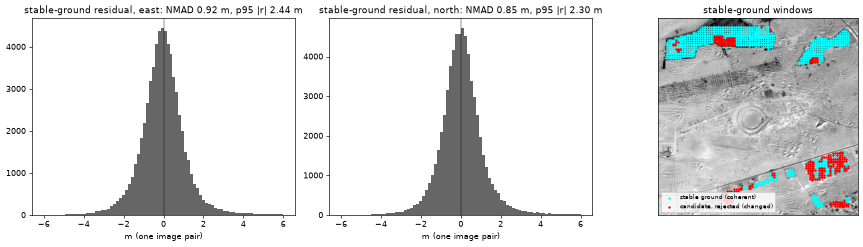

In [8]:
# WHAT THIS DOES: classifies windows (stable candidates, dune windows), selects coherent stable ground, estimates
# per-pair and per-image offsets, and reports the stable-ground residuals and the plane test.
med_pk, frac_valid = motion.coherence(D, PAIRS_OLI, PEAK_MIN, P["max_disp_px"])
STABLE_CAND = (F_AUTO >= P["stable_min_frac"]) & (F_MAN == 0)
STABLE = STABLE_CAND & (med_pk >= P["stable_min_med_peak"]) & (frac_valid >= P["stable_min_valid"])
STABLE_IDX = np.where(STABLE)[0]
print(f"stable-ground candidates {STABLE_CAND.sum()}, coherent in every OLI pair (kept) {STABLE.sum()}")

N_EP = len(SC)
offs = motion.pair_offsets(D, ALL_PAIRS, STABLE_IDX, PEAK_MIN, P["max_disp_px"], RES)
OFFS = pd.DataFrame(offs)
OFFS["kind"] = ["oli" if p in PAIRS_OLI else ("aux" if p in PAIRS_AUX else "l7") for p in ALL_PAIRS]
OFFS["a"] = SC.date.values[OFFS.i]; OFFS["b"] = SC.date.values[OFFS.j]
GE, GN, used_pairs, resE, resN = motion.epoch_registration(offs, N_EP)
SC["reg_offset_E_m"], SC["reg_offset_N_m"] = GE - GE[OLI[0]], GN - GN[OLI[0]]
print("per-pair stable-ground offsets (m), by pair type:")
print(OFFS.groupby("kind")[["n", "E", "N", "nmadE", "nmadN", "p95"]].describe().loc[:, (slice(None), ["min", "50%", "max"])].round(2).T.to_string())
print(f"closure of per-image offsets: RMS E {np.sqrt(np.mean(resE ** 2)):.3f} m, N {np.sqrt(np.mean(resN ** 2)):.3f} m over {len(used_pairs)} pairs")

# pooled stable-ground residuals after removing each image's offset (OLI network pairs)
resid_E, resid_N, grads = [], [], []
xs, ys = GRID.xy(rr, cc)
for (i, j) in PAIRS_OLI:
    dr_, dc_, pk_, _ = D[(i, j)]
    ok = STABLE & motion.valid_obs(D[(i, j)], PEAK_MIN, P["max_disp_px"])
    e = dc_[ok] * RES - (GE[j] - GE[i]); n = -dr_[ok] * RES - (GN[j] - GN[i])
    resid_E.append(e); resid_N.append(n)
    X = np.column_stack([np.ones(ok.sum()), (xs[ok] - xs.mean()) / 1e3, (ys[ok] - ys.mean()) / 1e3])
    grads.append(np.concatenate([np.linalg.lstsq(X, e, rcond=None)[0][1:], np.linalg.lstsq(X, n, rcond=None)[0][1:]]))
resid_E, resid_N, grads = np.concatenate(resid_E), np.concatenate(resid_N), np.array(grads)
rad = np.hypot(resid_E - np.median(resid_E), resid_N - np.median(resid_N))
noise = {"pairs": len(PAIRS_OLI), "n_residuals": int(resid_E.size), "nmad_E_m": round(float(tk.nmad(resid_E)), 3), "nmad_N_m": round(float(tk.nmad(resid_N)), 3),
         "p95_radial_m": round(float(np.percentile(rad, 95)), 2), "median_E_m": round(float(np.median(resid_E)), 3), "median_N_m": round(float(np.median(resid_N)), 3),
         "plane_gradient_median_abs_m_per_km": round(float(np.median(np.abs(grads))), 3), "plane_gradient_max_abs_m_per_km": round(float(np.abs(grads).max()), 3),
         "per_image_offset_closure_rms_m": [round(float(np.sqrt(np.mean(resE ** 2))), 3), round(float(np.sqrt(np.mean(resN ** 2))), 3)],
         "per_image_offset_range_E_m": [round(float(SC.reg_offset_E_m.min()), 2), round(float(SC.reg_offset_E_m.max()), 2)],
         "per_image_offset_range_N_m": [round(float(SC.reg_offset_N_m.min()), 2), round(float(SC.reg_offset_N_m.max()), 2)],
         "n_stable_windows": int(STABLE.sum())}
QC["stable_ground_pairwise"] = noise
print(json.dumps(noise, indent=1))
print("per-image offsets relative to the first OLI scene (m):")
print(SC[["date", "role", "sensor", "reg_offset_E_m", "reg_offset_N_m"]].round(2).to_string())
OFFS.round(3).to_csv(OUT / "02_pair_offsets.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
lim = 6
for a, v, nm in [(axes[0], resid_E, "east"), (axes[1], resid_N, "north")]:
    a.hist(v, bins=np.arange(-lim, lim + 0.01, 0.15), color="0.4")
    a.axvline(0, color="k", lw=0.5)
    a.set_title(f"stable-ground residual, {nm}: NMAD {tk.nmad(v):.2f} m, p95 |r| {np.percentile(np.abs(v - np.median(v)), 95):.2f} m")
    a.set_xlabel("m (one image pair)")
axes[2].imshow(base, cmap="gray", extent=extent(GRID))
axes[2].scatter(xs[STABLE], ys[STABLE], s=3, c="cyan", label="stable ground (coherent)")
axes[2].scatter(xs[STABLE_CAND & ~STABLE], ys[STABLE_CAND & ~STABLE], s=3, c="red", label="candidate, rejected (changed)")
axes[2].legend(loc="lower left", fontsize=7); axes[2].set_xticks([]); axes[2].set_yticks([]); axes[2].set_title("stable-ground windows")
plt.tight_layout(); plt.savefig(OUT / "02_stable_ground_residuals.png"); plt.show()

## 7 · Velocity of every dune window (Landsat 8/9 network)

A **dune window** has its centre inside the box and at most 25 % of its area in the non-dune mask. For each one, the registration-corrected displacements of all Landsat 8/9 pairs are combined into a position per year (east and north separately; pairs that do not close with the rest are dropped as outliers), and a straight line through the positions gives the velocity and its formal standard error.

**Is that standard error honest?** It is tested on stable ground that was *not* used for the registration: the stable windows are split at random into two halves, one half sets the registration, and the other half's "velocities" (which should be zero) are compared with their standard errors. The formal errors are then inflated by the factor that makes exactly 5 % of those held-out stable windows exceed the detection threshold (the formal errors alone would flag far more), so the threshold has a 5 % false-detection rate on ground that does not move. The difference between the two halves' registrations, expressed as a velocity, is added as a systematic term. Stable ground here is mostly established farms and older built-up areas; it is a conservative null because some of it changes slowly too.

**Detection limit.** A window's motion is **detected** only if its speed exceeds 2.45 σ (the 95 % level for a 2-D vector whose true value is zero), where σ is the calibrated per-component uncertainty. Otherwise it is **below the detection limit** and no speed or heading is reported for it.

In [9]:
# WHAT THIS DOES: inverts the OLI pair network for every dune window, calibrates the uncertainty on held-out stable
# ground, and decides per window whether motion is detected.
T, EL = SC.t.values, SC.sun_el.values
YE, YN, VV = motion.observations(D_D, PAIRS_OLI, DI, GE, GN, PEAK_MIN_D, P["max_disp_px"], RES)
t0 = time.time()
VEL = motion.velocities(YE, YN, VV, PAIRS_OLI, T, OLI)
print(f"{DUNE_IDX.size} dune windows inverted in {time.time() - t0:.1f} s")

NULLT = motion.held_out_null(D, PAIRS_OLI, PAIRS_OLI, OLI, STABLE_IDX, T, N_EP, PEAK_MIN, P["max_disp_px"], RES, seed=P["seed"])
F_NMAD = motion.calibration_factor(NULLT["vE"], NULLT["vN"], NULLT["sE"], NULLT["sN"])
SIG_SYS = float(np.hypot(NULLT["reg_velocity_diff_E"], NULLT["reg_velocity_diff_N"]) / np.sqrt(2))
_se0 = (NULLT["sE"] + NULLT["sN"]) / 2
F_CAL = float(np.nanpercentile(np.hypot(NULLT["vE"], NULLT["vN"]) / (motion.CHI2_2DOF_95 * _se0), 95))   # 5 % false detections
print(f"inflation factor from the robust (NMAD) scatter alone: {F_NMAD:.2f}; from the 95th percentile (used): {F_CAL:.2f}")
def sigma(sE, sN):
    """calibrated per-component 1-sigma velocity uncertainty (m/yr)"""
    return np.sqrt((F_CAL * (sE + sN) / 2) ** 2 + SIG_SYS ** 2)
null_sig = sigma(NULLT["sE"], NULLT["sN"])
null_speed = np.hypot(NULLT["vE"], NULLT["vN"])
null_fp = float(np.nanmean(null_speed > motion.CHI2_2DOF_95 * null_sig))
print(f"held-out stable ground: {np.isfinite(null_speed).sum()} windows; 'speed' median {np.nanmedian(null_speed):.3f}, "
      f"90th pct {np.nanpercentile(null_speed, 90):.3f}, 95th pct {np.nanpercentile(null_speed, 95):.3f} m/yr")
print(f"formal-error inflation factor F_CAL = {F_CAL:.2f}; systematic (registration from two halves) = {SIG_SYS:.4f} m/yr per component")
print(f"after calibration, {100 * null_fp:.1f} % of held-out stable windows would be called 'moving' (target 5 %)")

d_valid = (VEL["n_used"] >= P["dune_min_valid"] * len(PAIRS_OLI)) & (VEL["n_epochs"] >= max(4, len(OLI) // 2)) & np.isfinite(VEL["vE"]) & np.isfinite(VEL["vN"])
SPEED = np.hypot(VEL["vE"], VEL["vN"])
HEAD = tk.heading_deg(VEL["vE"], VEL["vN"])
SIG = sigma(VEL["sE"], VEL["sN"])
DL_W = motion.CHI2_2DOF_95 * SIG
DET = d_valid & (SPEED > DL_W)
DL_FIELD = float(np.nanmedian(DL_W[d_valid]))
QUAL = np.clip(np.nanmedian(np.stack([D_D[p][2] for p in PAIRS_OLI]), axis=0), 0, 1) * (VEL["n_used"] / len(PAIRS_OLI))
print(f"\nvalid dune windows: {d_valid.sum()} of {DUNE_IDX.size}; detection limit (2.45 sigma) per window: median {DL_FIELD:.3f}, "
      f"5-95 % {np.nanpercentile(DL_W[d_valid], 5):.3f}-{np.nanpercentile(DL_W[d_valid], 95):.3f} m/yr")
print(f"motion detected in {DET.sum()} windows ({100 * DET.sum() / d_valid.sum():.1f} % of valid); below detection limit: {(d_valid & ~DET).sum()}")
sd = SPEED[DET]
print(f"detected speeds: median {np.median(sd):.2f}, p10 {np.percentile(sd, 10):.2f}, p90 {np.percentile(sd, 90):.2f}, max {sd.max():.2f} m/yr")
print(f"network closure RMS (A->B + B->C vs A->C) on dune windows: median E {np.nanmedian(VEL['rmsE'][d_valid]):.2f} m, N {np.nanmedian(VEL['rmsN'][d_valid]):.2f} m; "
      f"pairs dropped as network outliers: {100 * VEL['outE'][d_valid].sum() / VV[d_valid].sum():.2f} % (E), {100 * VEL['outN'][d_valid].sum() / VV[d_valid].sum():.2f} % (N)")
QC["noise_and_detection"] = {
    "held_out_stable_windows": int(np.isfinite(null_speed).sum()),
    "held_out_stable_speed_median_myr": round(float(np.nanmedian(null_speed)), 3),
    "held_out_stable_speed_p90_myr": round(float(np.nanpercentile(null_speed, 90)), 3),
    "held_out_stable_speed_p95_myr": round(float(np.nanpercentile(null_speed, 95)), 3),
    "held_out_stable_vE_nmad_myr": round(float(tk.nmad(NULLT["vE"])), 3), "held_out_stable_vN_nmad_myr": round(float(tk.nmad(NULLT["vN"])), 3),
    "formal_error_inflation_factor": round(F_CAL, 2), "inflation_factor_nmad_only": round(F_NMAD, 2), "systematic_registration_myr": round(SIG_SYS, 4),
    "false_detection_rate_on_held_out_stable": round(null_fp, 3),
    "detection_limit_definition": "speed > 2.45 x calibrated per-component sigma (95 % for a 2-D null)",
    "detection_limit_median_myr": round(DL_FIELD, 3),
    "detection_limit_p5_p95_myr": [round(float(np.nanpercentile(DL_W[d_valid], 5)), 3), round(float(np.nanpercentile(DL_W[d_valid], 95)), 3)],
    "closure_rms_median_m": [round(float(np.nanmedian(VEL["rmsE"][d_valid])), 2), round(float(np.nanmedian(VEL["rmsN"][d_valid])), 2)],
}

2417 dune windows inverted in 0.4 s
inflation factor from the robust (NMAD) scatter alone: 2.66; from the 95th percentile (used): 3.35
held-out stable ground: 990 windows; 'speed' median 0.102, 90th pct 0.243, 95th pct 0.376 m/yr
formal-error inflation factor F_CAL = 3.35; systematic (registration from two halves) = 0.0128 m/yr per component
after calibration, 4.7 % of held-out stable windows would be called 'moving' (target 5 %)

valid dune windows: 2391 of 2417; detection limit (2.45 sigma) per window: median 0.454, 5-95 % 0.302-0.826 m/yr
motion detected in 1394 windows (58.3 % of valid); below detection limit: 997
detected speeds: median 0.67, p10 0.44, p90 1.14, max 2.86 m/yr
network closure RMS (A->B + B->C vs A->C) on dune windows: median E 1.03 m, N 0.48 m; pairs dropped as network outliers: 1.25 % (E), 0.85 % (N)


### What was rejected, and why

Every (window, pair) observation is either used or rejected for one reason, checked in this order: no data (cloud/shadow/fill, or more than 40 % of the window masked as non-dune, in either image), weak match (peak below the false-match threshold), displacement larger than the reliable unguided range, or network outlier (does not close with the other pairs). Whole windows are excluded if they are outside the box, mostly non-dune surface, or have too few valid pairs.

In [10]:
# WHAT THIS DOES: counts rejections per reason (windows and window-pair observations) and writes 02_rejections.csv.
rej_obs = {"no data (QA cloud/shadow/fill, or > 40 % masked)": 0, "weak match (peak < threshold)": 0, "displacement > max unguided range": 0, "network outlier": 0, "used": 0}
for p, (i, j) in enumerate(PAIRS_OLI):
    dr_, dc_, pk_, _ = D_D[(i, j)]
    nodata = ~np.isfinite(pk_)
    weak = ~nodata & (pk_ < PEAK_MIN_D)
    big = ~nodata & ~weak & (np.hypot(dr_, dc_) > P["max_disp_px"])
    outl = (VEL["outE"][:, p] | VEL["outN"][:, p]) & ~(nodata | weak | big)
    rej_obs["no data (QA cloud/shadow/fill, or > 40 % masked)"] += int(nodata.sum()); rej_obs["weak match (peak < threshold)"] += int(weak.sum())
    rej_obs["displacement > max unguided range"] += int(big.sum()); rej_obs["network outlier"] += int(outl.sum())
    rej_obs["used"] += int((~(nodata | weak | big | outl)).sum())
tot = sum(rej_obs.values())
rej_win = {"all windows on the grid": int(rr.size), "centre outside the box": int((~CIN).sum()),
           "inside box, > 25 % non-dune mask": int((CIN & (F_ND > P["dune_max_nondune"])).sum()),
           "dune window, too few valid pairs/epochs": int((~d_valid).sum()), "dune window, valid": int(d_valid.sum()),
           "  of which motion detected": int(DET.sum()), "  of which below detection limit": int((d_valid & ~DET).sum())}
REJ = pd.DataFrame([{"level": "window-pair observation (dune windows x OLI pairs)", "reason": k, "count": v, "pct": round(100 * v / tot, 2)} for k, v in rej_obs.items()]
                   + [{"level": "window", "reason": k, "count": v, "pct": round(100 * v / rr.size, 2)} for k, v in rej_win.items()])
print(REJ.to_string(index=False))
REJ.to_csv(OUT / "02_rejections.csv", index=False)
QC["rejections"] = {"observations": {k: {"count": v, "pct": round(100 * v / tot, 2)} for k, v in rej_obs.items()}, "windows": rej_win,
                    "pct_dune_windows_rejected": round(100 * (~d_valid).sum() / DUNE_IDX.size, 2),
                    "pct_observations_rejected": round(100 * (tot - rej_obs["used"]) / tot, 2)}

                                             level                                           reason  count    pct
window-pair observation (dune windows x OLI pairs) no data (QA cloud/shadow/fill, or > 40 % masked)      0   0.00
window-pair observation (dune windows x OLI pairs)                    weak match (peak < threshold)   2350   1.47
window-pair observation (dune windows x OLI pairs)                displacement > max unguided range     35   0.02
window-pair observation (dune windows x OLI pairs)                                  network outlier   2915   1.83
window-pair observation (dune windows x OLI pairs)                                             used 154222  96.68
                                            window                          all windows on the grid  10100 100.00
                                            window                           centre outside the box   3065  30.35
                                            window                 inside box, > 25 % no

## 8 · Is the signal real? Linearity with time and aliasing

If a dune moves steadily, displacement grows in proportion to the time between images; noise does not grow with time, and a match that jumped to the neighbouring dune would be off by about one dune spacing. Three checks:
1. **Short versus long pairs**: velocity from pairs ≤ 3.5 years apart (through the network) against velocity from pairs ≥ 8 years apart (direct). Aliasing would make the long-pair velocity differ by roughly spacing ÷ time.
2. **Displacement versus time separation**: for detected windows, the displacement of every pair projected on that window's direction of motion, binned by time separation. For stable ground the same plot should stay flat at zero.
3. **Dune spacing**: from the image autocorrelation over the dune windows, compared with the largest displacement measured.

detected windows with both: 1394; short-pair (27 pairs) vs long-pair (13 pairs) velocity: r = 0.89 (E), 0.94 (N); median difference -0.027/-0.017 m/yr; NMAD 0.132/0.076 m/yr
dune pattern (2-D power spectrum, 45-900 m): spectral peak at 85 m; 25 % of the variance is at wavelengths below 73 m
99th-percentile detected speed x 12.0 yr = 23.8 m = 0.28 of the dominant spacing
long-pair residuals vs short-pair prediction: median 1.86 m, 99th pct 13.57 m, share > half the small-dune spacing (37 m): 0.062 %
along-motion displacement vs time separation, detected windows: slope 0.721 m/yr, intercept +0.10 m; stable ground along the same direction: slope +0.012 m/yr


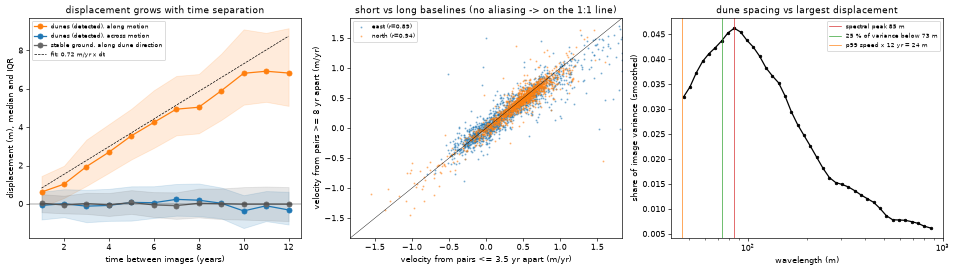

In [11]:
# WHAT THIS DOES: short- vs long-baseline velocities, displacement vs time separation (dunes and stable ground),
# and the dominant dune spacing from the image autocorrelation.
dt_pairs = np.array([T[j] - T[i] for i, j in PAIRS_OLI])
short = [k for k, d_ in enumerate(dt_pairs) if d_ <= 3.5]
long_ = [k for k, d_ in enumerate(dt_pairs) if d_ >= 8.0]
VS = motion.velocities(YE[:, short], YN[:, short], VV[:, short], [PAIRS_OLI[k] for k in short], T, OLI)
def direct_rate(Y, V, ks):
    r = np.where(V[:, ks], Y[:, ks] / dt_pairs[ks], np.nan)
    return np.nanmedian(r, axis=1)
vLE, vLN = direct_rate(YE, VV, long_), direct_rate(YN, VV, long_)
m = DET & np.isfinite(VS["vE"]) & np.isfinite(vLE)
dE, dN = vLE[m] - VS["vE"][m], vLN[m] - VS["vN"][m]
r_short_long = [float(np.corrcoef(VS["vE"][m], vLE[m])[0, 1]), float(np.corrcoef(VS["vN"][m], vLN[m])[0, 1])]
print(f"detected windows with both: {m.sum()}; short-pair ({len(short)} pairs) vs long-pair ({len(long_)} pairs) velocity: "
      f"r = {r_short_long[0]:.2f} (E), {r_short_long[1]:.2f} (N); median difference {np.median(dE):+.3f}/{np.median(dN):+.3f} m/yr; "
      f"NMAD {tk.nmad(dE):.3f}/{tk.nmad(dN):.3f} m/yr")

# residual of every long pair against the velocity predicted from short pairs (in metres): an alias would sit near +-spacing
resid_long = []
for k in long_:
    pred_E, pred_N = VS["vE"] * dt_pairs[k], VS["vN"] * dt_pairs[k]
    ok = VV[:, k] & DET & np.isfinite(pred_E)
    resid_long.append(np.hypot(YE[ok, k] - pred_E[ok], YN[ok, k] - pred_N[ok]))
resid_long = np.concatenate(resid_long)

# dune spacing: power spectrum of the high-passed latest image over the valid dune windows; the wavelength of the
# spectral peak (after smoothing, between 45 m and 900 m) is the dominant crest-to-crest spacing, and the 25th
# percentile of the power-weighted wavelength distribution stands for the small dunes
hp_img = np.nan_to_num(IMGS[LATEST] - ndimage.gaussian_filter(np.nan_to_num(IMGS[LATEST], nan=np.nanmean(IMGS[LATEST])), 30), nan=0.0)
dmask = np.zeros(hp_img.shape, bool)
for r_, c_ in zip(rr[DUNE_IDX][d_valid], cc[DUNE_IDX][d_valid]):
    dmask[r_ - 4:r_ + 4, c_ - 4:c_ + 4] = True
x_ = np.where(dmask, hp_img - hp_img[dmask].mean(), 0.0)
pw = np.fft.fftshift(np.abs(np.fft.fft2(x_)) ** 2)
fy = np.fft.fftshift(np.fft.fftfreq(x_.shape[0], RES)); fx = np.fft.fftshift(np.fft.fftfreq(x_.shape[1], RES))
FX, FY = np.meshgrid(fx, fy); FR = np.hypot(FX, FY)
lam_edges = np.geomspace(45, 900, 41)
lam_c = np.sqrt(lam_edges[1:] * lam_edges[:-1])
spec = np.array([pw[(FR <= 1 / lam_edges[k]) & (FR > 1 / lam_edges[k + 1])].sum() for k in range(len(lam_c))])
spec_s = ndimage.gaussian_filter1d(spec / spec.sum(), 1.0)
SPACING_M = float(lam_c[np.argmax(spec_s)])
cum = np.cumsum(spec / spec.sum())
SPACING_SMALL_M = float(lam_c[np.searchsorted(cum, 0.25)])
max_disp_12y = float(np.nanpercentile(SPEED[DET], 99) * (T[OLI[-1]] - T[OLI[0]]))
print(f"dune pattern (2-D power spectrum, 45-900 m): spectral peak at {SPACING_M:.0f} m; 25 % of the variance is at wavelengths below {SPACING_SMALL_M:.0f} m")
print(f"99th-percentile detected speed x {T[OLI[-1]] - T[OLI[0]]:.1f} yr = {max_disp_12y:.1f} m = {max_disp_12y / SPACING_M:.2f} of the dominant spacing")
print(f"long-pair residuals vs short-pair prediction: median {np.median(resid_long):.2f} m, 99th pct {np.percentile(resid_long, 99):.2f} m, "
      f"share > half the small-dune spacing ({SPACING_SMALL_M / 2:.0f} m): {100 * np.mean(resid_long > SPACING_SMALL_M / 2):.3f} %")

# displacement vs time separation (projected on each window's direction of motion)
u_E, u_N = VEL["vE"] / SPEED, VEL["vN"] / SPEED
along, across, dts = [], [], []
for k in range(len(PAIRS_OLI)):
    ok = VV[:, k] & DET
    along.append(YE[ok, k] * u_E[ok] + YN[ok, k] * u_N[ok]); across.append(-YE[ok, k] * u_N[ok] + YN[ok, k] * u_E[ok]); dts.append(np.full(ok.sum(), dt_pairs[k]))
along, across, dts = np.concatenate(along), np.concatenate(across), np.concatenate(dts)
# the same for held-out-style stable ground, projected on the field-median dune direction
fmE, fmN = np.median(VEL["vE"][DET]), np.median(VEL["vN"][DET]); fu = np.array([fmE, fmN]) / np.hypot(fmE, fmN)
sYE, sYN, sV = motion.observations(D, PAIRS_OLI, STABLE_IDX, GE, GN, PEAK_MIN, P["max_disp_px"], RES)
s_al = np.concatenate([sYE[sV[:, k], k] * fu[0] + sYN[sV[:, k], k] * fu[1] for k in range(len(PAIRS_OLI))])
s_dt = np.concatenate([np.full(sV[:, k].sum(), dt_pairs[k]) for k in range(len(PAIRS_OLI))])
bins = np.arange(0.5, 13.0, 1.0)
def binned(x, d):
    idx = np.digitize(d, bins)
    return np.array([[np.median(x[idx == b]), np.percentile(x[idx == b], 25), np.percentile(x[idx == b], 75)] if (idx == b).sum() > 20 else [np.nan] * 3 for b in range(1, len(bins))])
B_al, B_ac, B_st = binned(along, dts), binned(across, dts), binned(s_al, s_dt)
bc = 0.5 * (bins[1:] + bins[:-1])
slope_al = float(np.polyfit(dts, along, 1)[0]); icpt_al = float(np.polyfit(dts, along, 1)[1])
print(f"along-motion displacement vs time separation, detected windows: slope {slope_al:.3f} m/yr, intercept {icpt_al:+.2f} m; "
      f"stable ground along the same direction: slope {np.polyfit(s_dt, s_al, 1)[0]:+.3f} m/yr")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
a = axes[0]
for B, lab, col in [(B_al, "dunes (detected), along motion", "C1"), (B_ac, "dunes (detected), across motion", "C0"), (B_st, "stable ground, along dune direction", "0.4")]:
    a.plot(bc, B[:, 0], "o-", color=col, label=lab); a.fill_between(bc, B[:, 1], B[:, 2], color=col, alpha=0.15)
a.plot(bc, slope_al * bc + icpt_al, "k--", lw=0.8, label=f"fit: {slope_al:.2f} m/yr x dt")
a.axhline(0, color="k", lw=0.4); a.set_xlabel("time between images (years)"); a.set_ylabel("displacement (m), median and IQR")
a.set_title("displacement grows with time separation"); a.legend(fontsize=7)
a = axes[1]
lim_ = np.nanpercentile(np.abs(np.r_[VS["vE"][m], VS["vN"][m], vLE[m], vLN[m]]), 99)
a.scatter(VS["vE"][m], vLE[m], s=2, alpha=0.4, label=f"east (r={r_short_long[0]:.2f})"); a.scatter(VS["vN"][m], vLN[m], s=2, alpha=0.4, label=f"north (r={r_short_long[1]:.2f})")
a.plot([-lim_, lim_], [-lim_, lim_], "k-", lw=0.5); a.set_xlim(-lim_, lim_); a.set_ylim(-lim_, lim_)
a.set_xlabel("velocity from pairs <= 3.5 yr apart (m/yr)"); a.set_ylabel("velocity from pairs >= 8 yr apart (m/yr)"); a.legend(fontsize=7)
a.set_title("short vs long baselines (no aliasing -> on the 1:1 line)")
a = axes[2]
a.semilogx(lam_c, spec_s, "k.-"); a.axvline(SPACING_M, color="C3", lw=0.8, label=f"spectral peak {SPACING_M:.0f} m")
a.axvline(SPACING_SMALL_M, color="C2", lw=0.8, label=f"25 % of variance below {SPACING_SMALL_M:.0f} m")
a.axvline(max(max_disp_12y, 46), color="C1", lw=0.8, label=f"p99 speed x 12 yr = {max_disp_12y:.0f} m")
a.set_xlabel("wavelength (m)"); a.set_ylabel("share of image variance (smoothed)"); a.set_title("dune spacing vs largest displacement"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "02_displacement_vs_time.png"); plt.show()
QC["linearity_aliasing"] = {
    "short_pairs_max_dt_yr": 3.5, "long_pairs_min_dt_yr": 8.0, "n_short_pairs": len(short), "n_long_pairs": len(long_),
    "windows_compared": int(m.sum()), "corr_short_vs_long_E_N": [round(x, 3) for x in r_short_long],
    "median_diff_long_minus_short_myr_E_N": [round(float(np.median(dE)), 3), round(float(np.median(dN)), 3)],
    "nmad_diff_myr_E_N": [round(float(tk.nmad(dE)), 3), round(float(tk.nmad(dN)), 3)],
    "along_motion_slope_myr": round(slope_al, 3), "along_motion_intercept_m": round(icpt_al, 2),
    "stable_ground_slope_myr": round(float(np.polyfit(s_dt, s_al, 1)[0]), 4),
    "dune_spacing_spectral_peak_m": round(SPACING_M), "dune_spacing_25pct_variance_below_m": round(SPACING_SMALL_M),
    "p99_speed_times_baseline_m": round(max_disp_12y, 1),
    "long_pair_residual_vs_short_prediction_median_m": round(float(np.median(resid_long)), 2),
    "long_pair_residual_p99_m": round(float(np.percentile(resid_long, 99)), 2),
    "long_pair_residual_share_gt_half_small_spacing_pct": round(100 * float(np.mean(resid_long > SPACING_SMALL_M / 2)), 3),
}

## 9 · Illumination bias

At low November sun, dune images are mostly shading. If the sun is lower in one image, shadow edges move, and the matcher can report that as motion, in a direction tied to the sun azimuth (~150-155° here), not to the wind. The illumination-test pairs (a few weeks apart, sun elevation 3-12° different) measure this directly: the true motion over a few weeks is at most a few centimetres (detected speed × Δt, subtracted anyway), so what remains is the illumination artefact plus noise. Two estimates:
- **field level**: the median apparent displacement of the dune windows in each test pair against that pair's sun-elevation difference (slope in m per degree);
- **per window**: a slope for each dune window across all test pairs, compared with the same statistic on stable ground.

Then the consequences: the OLI network's sun elevations drift a little with time, so a slope b (m/deg) leaks into velocity as b × (d elevation/d time); and the Landsat 7 scenes are ~5° lower than the OLI average, which shifts their positions by b × Δel. Finally, a joint regression over the OLI pairs asks whether displacement follows time or sun-elevation difference.

         a          b  dt_days  d_sun_el  d_sun_az  dune_med_E_m  dune_med_N_m  dune_nmad_E_m  dune_nmad_N_m
2013-11-07 2013-12-09       32     -6.78      1.05          0.15         -0.60           0.89           0.67
2014-10-09 2014-11-10       32     -9.23      8.92         -0.13         -0.60           1.09           0.95
2014-11-10 2014-11-26       16     -3.79      1.14         -1.22         -0.30           1.36           0.64
2015-10-12 2015-11-13       32     -9.14      8.13         -0.30         -0.30           1.33           0.67
2015-11-13 2015-12-15       32     -5.91     -0.02         -0.27         -0.34           0.81           0.61
2016-10-14 2016-11-15       32     -9.04      7.29         -0.19         -0.48           0.49           0.49
2016-11-15 2016-12-01       16     -3.41      0.50         -0.61         -0.30           1.52           0.67
2017-10-01 2017-11-02       32     -9.28     11.27         -0.29         -0.49           0.88           0.68
2017-11-02 2017-12-

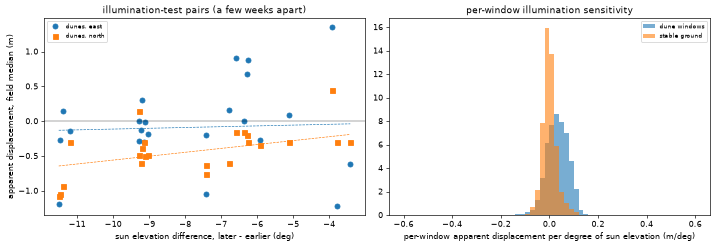

In [12]:
# WHAT THIS DOES: measures apparent displacement vs sun-elevation difference on the short illumination-test pairs,
# per window and field-wide, and propagates it to the velocities and to the Landsat 7 positions.
ill = []
AE_w, AN_w, DEL = [], [], []
for (i, j) in PAIRS_AUX:
    y_E, y_N, v_ = motion.observations(D_D, [(i, j)], DI, GE, GN, PEAK_MIN_D, P["max_disp_px"], RES)
    dt_ = T[j] - T[i]; del_ = EL[j] - EL[i]
    aE = np.where(v_[:, 0], y_E[:, 0] - np.where(DET, VEL["vE"], 0) * dt_, np.nan)
    aN = np.where(v_[:, 0], y_N[:, 0] - np.where(DET, VEL["vN"], 0) * dt_, np.nan)
    sE_, sN_, sv_ = motion.observations(D, [(i, j)], STABLE_IDX, GE, GN, PEAK_MIN, P["max_disp_px"], RES)
    AE_w.append(aE); AN_w.append(aN); DEL.append(del_)
    ill.append(dict(a=SC.date[i], b=SC.date[j], dt_days=round(dt_ * 365.25), d_sun_el=round(del_, 2), d_sun_az=round(SC.sun_az[j] - SC.sun_az[i], 2),
                    dune_med_E_m=np.nanmedian(aE[d_valid]), dune_med_N_m=np.nanmedian(aN[d_valid]),
                    dune_nmad_E_m=tk.nmad(aE[d_valid]), dune_nmad_N_m=tk.nmad(aN[d_valid])))
ILL = pd.DataFrame(ill)
print(ILL.round(2).to_string(index=False))
DEL = np.array(DEL); AE_w = np.array(AE_w).T; AN_w = np.array(AN_w).T
def slope0(y, x):
    ok = np.isfinite(y)
    return np.sum(y[ok] * x[ok]) / np.sum(x[ok] ** 2) if ok.sum() >= 5 else np.nan
bE_field = slope0(ILL.dune_med_E_m.values, DEL); bN_field = slope0(ILL.dune_med_N_m.values, DEL)
boot = np.random.default_rng(P["seed"]).integers(0, len(DEL), (2000, len(DEL)))
bE_ci = np.percentile([slope0(ILL.dune_med_E_m.values[b_], DEL[b_]) for b_ in boot], [2.5, 97.5])
bN_ci = np.percentile([slope0(ILL.dune_med_N_m.values[b_], DEL[b_]) for b_ in boot], [2.5, 97.5])
print(f"\nfield-level apparent displacement per degree of sun elevation (through the origin): "
      f"E {bE_field:+.3f} m/deg [95 % CI {bE_ci[0]:+.3f}, {bE_ci[1]:+.3f}], N {bN_field:+.3f} m/deg [{bN_ci[0]:+.3f}, {bN_ci[1]:+.3f}]")
bw_E = np.array([slope0(AE_w[w], DEL) for w in range(DUNE_IDX.size)])
bw_N = np.array([slope0(AN_w[w], DEL) for w in range(DUNE_IDX.size)])
# per-window slopes on stable ground for comparison
sAE, sAN = [], []
for (i, j) in PAIRS_AUX:
    sE_, sN_, sv_ = motion.observations(D, [(i, j)], STABLE_IDX, GE, GN, PEAK_MIN, P["max_disp_px"], RES)
    sAE.append(np.where(sv_[:, 0], sE_[:, 0], np.nan)); sAN.append(np.where(sv_[:, 0], sN_[:, 0], np.nan))
sAE, sAN = np.array(sAE).T, np.array(sAN).T
sbw = np.concatenate([[slope0(sAE[w], DEL) for w in range(STABLE_IDX.size)], [slope0(sAN[w], DEL) for w in range(STABLE_IDX.size)]])
print(f"per-window slopes, dunes: NMAD {tk.nmad(bw_E[d_valid]):.3f} (E) {tk.nmad(bw_N[d_valid]):.3f} (N) m/deg; "
      f"95th pct |b| {np.nanpercentile(np.abs(np.r_[bw_E[d_valid], bw_N[d_valid]]), 95):.3f} m/deg; stable ground NMAD {tk.nmad(sbw):.3f} m/deg")
# consequences
el_trend = float(np.polyfit(T[OLI], EL[OLI], 1)[0])
vel_bias_w = np.hypot(bw_E, bw_N) * abs(el_trend)
l7_del = float(np.mean(EL[ETM]) - np.mean(EL[OLI])) if ETM else np.nan
print(f"OLI sun-elevation trend {el_trend:+.3f} deg/yr -> velocity bias = |b| x trend: field {np.hypot(bE_field, bN_field) * abs(el_trend):.4f} m/yr; "
      f"per window 95th pct {np.nanpercentile(vel_bias_w[d_valid], 95):.4f} m/yr")
if ETM:
    print(f"Landsat 7 vs OLI mean sun elevation: {l7_del:+.2f} deg -> position shift at the L7 epochs: field {np.hypot(bE_field, bN_field) * abs(l7_del):.2f} m, "
          f"per window 95th pct {np.nanpercentile(np.hypot(bw_E, bw_N)[d_valid] * abs(l7_del), 95):.2f} m")
# joint regression over the OLI pairs: field-median along-direction displacement ~ c1 dt + c2 d_el
al_med = []
for k in range(len(PAIRS_OLI)):
    ok = VV[:, k] & DET
    al_med.append(np.median(YE[ok, k] * fu[0] + YN[ok, k] * fu[1]))
X = np.column_stack([dt_pairs, [EL[j] - EL[i] for i, j in PAIRS_OLI]])
coef, *_ = np.linalg.lstsq(X, np.array(al_med), rcond=None)
res_ = np.array(al_med) - X @ coef
cov = (res_ @ res_) / (len(al_med) - 2) * np.linalg.inv(X.T @ X)
print(f"OLI pairs, field-median displacement along the mean dune direction = {coef[0]:.3f} (+-{np.sqrt(cov[0, 0]):.3f}) m/yr x dt "
      f"+ {coef[1]:+.3f} (+-{np.sqrt(cov[1, 1]):.3f}) m/deg x d_el")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
a = axes[0]
a.plot(ILL.d_sun_el, ILL.dune_med_E_m, "o", label="dunes, east"); a.plot(ILL.d_sun_el, ILL.dune_med_N_m, "s", label="dunes, north")
xx_ = np.linspace(DEL.min(), DEL.max(), 10)
a.plot(xx_, bE_field * xx_, "C0--", lw=0.8); a.plot(xx_, bN_field * xx_, "C1--", lw=0.8)
a.axhline(0, color="k", lw=0.4); a.set_xlabel("sun elevation difference, later - earlier (deg)"); a.set_ylabel("apparent displacement, field median (m)")
a.set_title("illumination-test pairs (a few weeks apart)"); a.legend(fontsize=7)
a = axes[1]
a.hist(np.r_[bw_E[d_valid], bw_N[d_valid]], bins=np.linspace(-0.6, 0.6, 61), alpha=0.6, density=True, label="dune windows")
a.hist(sbw[np.isfinite(sbw)], bins=np.linspace(-0.6, 0.6, 61), alpha=0.6, density=True, label="stable ground")
a.set_xlabel("per-window apparent displacement per degree of sun elevation (m/deg)"); a.legend(fontsize=7); a.set_title("per-window illumination sensitivity")
plt.tight_layout(); plt.savefig(OUT / "02_illumination_test.png"); plt.show()
QC["illumination"] = {
    "n_test_pairs": len(PAIRS_AUX), "d_sun_el_range_deg": [round(float(DEL.min()), 2), round(float(DEL.max()), 2)],
    "field_slope_m_per_deg_E_N": [round(bE_field, 4), round(bN_field, 4)],
    "field_slope_95ci_E": [round(float(x), 4) for x in bE_ci], "field_slope_95ci_N": [round(float(x), 4) for x in bN_ci],
    "per_window_slope_nmad_dunes_m_per_deg": [round(float(tk.nmad(bw_E[d_valid])), 3), round(float(tk.nmad(bw_N[d_valid])), 3)],
    "per_window_slope_nmad_stable_m_per_deg": round(float(tk.nmad(sbw)), 3),
    "oli_sun_el_trend_deg_per_yr": round(el_trend, 4),
    "velocity_bias_field_myr": round(float(np.hypot(bE_field, bN_field) * abs(el_trend)), 4),
    "velocity_bias_per_window_p95_myr": round(float(np.nanpercentile(vel_bias_w[d_valid], 95)), 4),
    "l7_minus_oli_sun_el_deg": round(l7_del, 2) if ETM else None,
    "joint_regression_oli_pairs": {"dt_coef_myr": round(float(coef[0]), 4), "dt_coef_se": round(float(np.sqrt(cov[0, 0])), 4),
                                   "d_el_coef_m_per_deg": round(float(coef[1]), 4), "d_el_coef_se": round(float(np.sqrt(cov[1, 1])), 4)},
    "table": ILL.round(3).to_dict("records"),
}
ILL.round(3).to_csv(OUT / "02_illumination_pairs.csv", index=False)

## 10 · Year-to-year variability

Single-window yearly displacements are far below the per-pair noise (about a metre), so the interannual range can only be judged on the **field median**. For each interval between consecutive confirmed Landsat 8/9 scenes, the median velocity along the field's mean direction is computed for the detected windows, corrected for the illumination slope of section 9, and compared with (a) the same quantity on stable ground, which shows how much a field median varies from noise alone, and (b) the MERRA-2 sand-drift of the same interval projected on the same direction (from notebook 01's cached hourly wind), as a physical cross-check. Stable ground cannot show errors that affect only the dunes (shading, haze, the appearance of sand), so its spread is only a lower bound. The deciding noise reference is the field-median displacement of the dunes themselves in the illumination-test pairs, which are only weeks apart (true motion ≈ 0) once the illumination slope is removed.

In [13]:
# WHAT THIS DOES: field-median velocity for each consecutive-year interval (dunes vs stable ground), to decide
# whether year-to-year changes are above the noise.
PE, PN = VEL["PE"], VEL["PN"]
tl = VEL["t"]
iv = []
sYE2, sYN2, sV2 = motion.observations(D, PAIRS_OLI, STABLE_IDX, GE, GN, PEAK_MIN, P["max_disp_px"], RES)
SV = motion.velocities(sYE2, sYN2, sV2, PAIRS_OLI, T, OLI)
for k in range(len(OLI) - 1):
    d_ = tl[k + 1] - tl[k]
    a_ = ((PE[DET, k + 1] - PE[DET, k]) * fu[0] + (PN[DET, k + 1] - PN[DET, k]) * fu[1]) / d_
    s_ = ((SV["PE"][:, k + 1] - SV["PE"][:, k]) * fu[0] + (SV["PN"][:, k + 1] - SV["PN"][:, k]) * fu[1]) / d_
    iv.append(dict(start=SC.date[OLI[k]], end=SC.date[OLI[k + 1]], years=round(d_, 2), dune_median_myr=np.nanmedian(a_), stable_median_myr=np.nanmedian(s_)))
IV = pd.DataFrame(iv)
# remove the illumination artefact measured in section 9 (field slope along the dune direction x change in sun elevation)
b_al = bE_field * fu[0] + bN_field * fu[1]
IV["d_sun_el"] = [EL[OLI[k + 1]] - EL[OLI[k]] for k in range(len(OLI) - 1)]
IV["dune_median_illum_corrected_myr"] = IV.dune_median_myr - b_al * IV.d_sun_el / IV.years
# wind over the same intervals: MERRA-2 hourly resultant drift (Fryberger weighting) projected on the dune direction
wfiles = [f for f in sorted(RAW.glob("merra2_u10v10_hourly_i*_j*.csv")) if "-" not in f.stem.split("_j")[-1]]
if wfiles:
    hw = pd.read_csv(wfiles[0], parse_dates=["time"]).dropna()
    hw["time"] = pd.to_datetime(hw["time"], utc=True).dt.tz_localize(None)
    w_ = wind.weighting(wind.speed_kt(hw.U10M.values, hw.V10M.values))
    to = np.radians(wind.downwind_deg(hw.U10M.values, hw.V10M.values))
    qE, qN = w_ * np.sin(to) / 100.0, w_ * np.cos(to) / 100.0   # per hour; mean over hours = drift rate in VU/yr
    wend = hw.time.max()
    wa = []
    for k in range(len(OLI) - 1):
        a0, a1 = pd.Timestamp(SC.date[OLI[k]]), pd.Timestamp(SC.date[OLI[k + 1]])
        sel_ = (hw.time >= a0) & (hw.time < a1)
        wa.append(np.mean(qE[sel_]) * fu[0] + np.mean(qN[sel_]) * fu[1] if a1 <= wend + pd.Timedelta(days=1) else np.nan)
    IV["wind_drift_along_dune_dir_VU_per_yr"] = wa
print(IV.round(3).to_string(index=False))
okw = IV.wind_drift_along_dune_dir_VU_per_yr.notna() if "wind_drift_along_dune_dir_VU_per_yr" in IV else pd.Series(False, index=IV.index)
if okw.sum() >= 5:
    r_w, p_w = stats.pearsonr(IV.dune_median_illum_corrected_myr[okw], IV.wind_drift_along_dune_dir_VU_per_yr[okw])
    rs_w, ps_w = stats.spearmanr(IV.dune_median_illum_corrected_myr[okw], IV.wind_drift_along_dune_dir_VU_per_yr[okw])
    print(f"dune interval medians vs MERRA-2 drift along the dune direction ({okw.sum()} intervals): Pearson r = {r_w:.2f} (p = {p_w:.3f}), Spearman {rs_w:.2f} (p = {ps_w:.3f})")
else:
    r_w = p_w = rs_w = ps_w = np.nan
sd_d, sd_s = IV.dune_median_illum_corrected_myr.std(ddof=1), IV.stable_median_myr.std(ddof=1)
F_ratio = (sd_d / sd_s) ** 2
p_F = 1 - stats.f.cdf(F_ratio, len(IV) - 1, len(IV) - 1)
print(f"spread of interval medians: dunes SD {sd_d:.3f} m/yr, stable ground SD {sd_s:.3f} m/yr (variance ratio {F_ratio:.2f}, one-sided p = {p_F:.3f})")
# a dune-specific noise reference: the field-median displacement of the dune windows in the illumination-test pairs (weeks
# apart, so true motion ~0), after removing the illumination slope. Its scatter is the noise of a field-median position
# difference between two dates ON DUNES (stable ground cannot show dune-only errors).
aux_al = (ILL.dune_med_E_m * fu[0] + ILL.dune_med_N_m * fu[1]) - b_al * ILL.d_sun_el
SD_PAIR = float(np.std(aux_al, ddof=1))
sig_iv = SD_PAIR / IV.years.values
xw_ = IV.dune_median_illum_corrected_myr.values
mu_w = np.sum(xw_ / sig_iv ** 2) / np.sum(1 / sig_iv ** 2)
chi2_ = float(np.sum(((xw_ - mu_w) / sig_iv) ** 2)); p_chi = float(1 - stats.chi2.cdf(chi2_, len(xw_) - 1))
print(f"dune-specific noise of a field-median displacement between two dates (illumination-test pairs): SD {SD_PAIR:.2f} m "
      f"-> about {SD_PAIR:.2f} m/yr for a one-year interval; chi-square of the interval medians about their mean: {chi2_:.1f} on {len(xw_) - 1} dof, p = {p_chi:.3f}")
IV_ABOVE_NOISE = bool(p_chi < 0.05)
FIELD_COMMON_V_ERR = float(SD_PAIR / np.sqrt(2) / np.sqrt(np.sum((VEL["t"] - VEL["t"].mean()) ** 2)))
print(f"the same dune-only epoch noise, common to all windows, limits the field-median velocity to +-{FIELD_COMMON_V_ERR:.3f} m/yr (1 sigma)")
print("interannual variability above the dune-specific noise:", IV_ABOVE_NOISE)
QC["interannual"] = {"intervals": IV.round(4).to_dict("records"), "dune_sd_myr": round(float(sd_d), 4), "stable_sd_myr": round(float(sd_s), 4),
                     "variance_ratio_vs_stable": round(float(F_ratio), 2), "p_value_vs_stable": round(float(p_F), 4),
                     "dune_pair_noise_sd_m": round(SD_PAIR, 3), "chi2_vs_dune_noise": round(chi2_, 2), "p_value_vs_dune_noise": round(p_chi, 4),
                     "above_noise": IV_ABOVE_NOISE, "field_median_velocity_common_error_myr": round(FIELD_COMMON_V_ERR, 4),
                     "decision": "judged against the dune-specific noise from the illumination-test pairs (the stable-ground spread is a lower bound)",
                     "illumination_slope_along_dune_dir_m_per_deg": round(float(b_al), 4),
                     "dune_interval_median_range_myr_illum_corrected": [round(float(IV.dune_median_illum_corrected_myr.min()), 3), round(float(IV.dune_median_illum_corrected_myr.max()), 3)],
                     "wind_correlation": {"pearson_r": round(float(r_w), 3), "pearson_p": round(float(p_w), 4), "spearman_r": round(float(rs_w), 3), "spearman_p": round(float(ps_w), 4),
                                          "n_intervals": int(okw.sum()), "note": "MERRA-2 hourly 10 m wind, Fryberger weighting, resultant drift per interval projected on the field-mean dune direction"}}
IV.round(4).to_csv(OUT / "02_interannual.csv", index=False)

     start        end  years  dune_median_myr  stable_median_myr  d_sun_el  dune_median_illum_corrected_myr  wind_drift_along_dune_dir_VU_per_yr
2013-11-07 2014-11-10   1.01           -0.002              0.019    -0.890                            0.046                                0.058
2014-11-10 2015-11-13   1.01            0.611              0.000    -0.727                            0.650                                0.201
2015-11-13 2016-11-15   1.01            0.081             -0.028    -0.676                            0.117                               -0.023
2016-11-15 2017-11-02   0.96            0.833              0.115     3.529                            0.633                                0.178
2017-11-02 2019-11-08   2.02            0.932             -0.031    -1.511                            0.973                                0.174
2019-11-08 2020-11-10   1.01            0.330              0.018    -0.742                            0.370                       

## 11 · Landsat 7 (2000, 2001) as a long-baseline check

The Landsat 7 scenes are not in the velocity network: they come from a different sensor (ETM+ pan, 0.52-0.90 µm, against OLI's 0.50-0.68 µm), with ~5° lower sun, and 12-25 years before the OLI scenes, during which the farms and the settlement changed (so their stable ground is poorer). They are used only to test the OLI velocities: for each dune window, its position in 2000/2001 is measured directly (median over its matches with the 12 OLI scenes, after removing the Landsat 7 image offset from stable ground) and compared with the position the OLI line predicts for that date. If the OLI velocity is right and steady, the difference should be near zero; aliasing would show up as differences near a dune spacing.

                                             0           1
scene                               2000-11-27  2001-11-30
n_valid_windows                           2081        2124
share_of_valid_dune_windows               0.87       0.888
n_stable_windows_for_offset                118         179
offset_E_m                                2.77        1.24
offset_N_m                                0.49        1.07
median_misfit_E_m                        -1.65       -2.03
median_misfit_N_m                          0.1       -1.76
nmad_misfit_E_m                           4.21        4.31
nmad_misfit_N_m                           3.54        3.29
misfit_p95_m                              13.6       13.64
share_misfit_gt_half_small_spacing      0.0043      0.0028
median_misfit_as_velocity_myr            0.087       0.149



windows with a usable 2000 position: 2081 of 2391 valid (87 %); detected among them: 1260


2000-2025 vs 2013-2025 velocity on detected windows: r = 0.87 (E), 0.91 (N); median speed 0.68 vs 0.65 m/yr; median difference E +0.061, N +0.019 m/yr


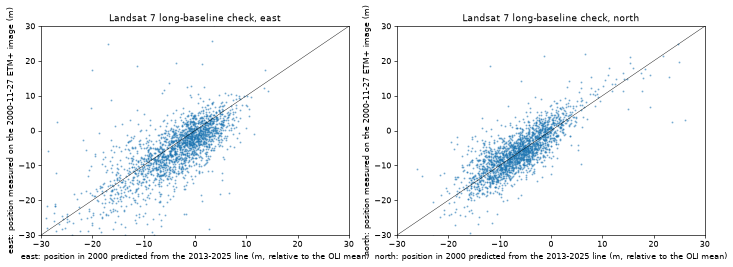

In [14]:
# WHAT THIS DOES: positions of every dune window at the Landsat 7 epochs, compared with the extrapolated OLI line,
# and a 2000-2025 velocity where the Landsat 7 match holds.
l7_rows = []
L7POS = {}
if ETM:
    tl = VEL["t"]
    PE, PN = VEL["PE"], VEL["PN"]
    # OLI line: a + v t with a = mean(P) - v mean(t) over each window's valid epochs
    okP = np.isfinite(PE) & np.isfinite(PN)
    tbar = np.array([tl[o].mean() if o.any() else np.nan for o in okP])
    aE = np.nanmean(np.where(okP, PE, np.nan), axis=1) - VEL["vE"] * tbar
    aN = np.nanmean(np.where(okP, PN, np.nan), axis=1) - VEL["vN"] * tbar
    for e in ETM:
        prs = [(e, k) for k in OLI]
        yE_, yN_, v_ = motion.observations(D_D, prs, DI, GE, GN, PEAK_MIN_D, P["max_disp_px"], RES)
        # position at the ETM epoch = P_k - y(e->k), in the same frame as the OLI positions
        posE = np.where(v_, PE - yE_, np.nan); posN = np.where(v_, PN - yN_, np.nan)
        nval = v_.sum(axis=1)
        pE, pN = np.nanmedian(posE, axis=1), np.nanmedian(posN, axis=1)
        prE, prN = aE + VEL["vE"] * T[e], aN + VEL["vN"] * T[e]
        L7POS[e] = (pE, pN, nval)
        okw = d_valid & (nval >= 3)
        dE_, dN_ = pE - prE, pN - prN
        span = np.mean(tl) - T[e]
        l7_rows.append(dict(scene=SC.date[e], n_valid_windows=int(okw.sum()), share_of_valid_dune_windows=round(okw.sum() / d_valid.sum(), 3),
                            n_stable_windows_for_offset=int(OFFS[(OFFS.i == e) & OFFS.j.isin(OLI)].n.median()),
                            offset_E_m=round(float(SC.reg_offset_E_m[e]), 2), offset_N_m=round(float(SC.reg_offset_N_m[e]), 2),
                            median_misfit_E_m=round(float(np.nanmedian(dE_[okw])), 2), median_misfit_N_m=round(float(np.nanmedian(dN_[okw])), 2),
                            nmad_misfit_E_m=round(float(tk.nmad(dE_[okw])), 2), nmad_misfit_N_m=round(float(tk.nmad(dN_[okw])), 2),
                            misfit_p95_m=round(float(np.nanpercentile(np.hypot(dE_, dN_)[okw], 95)), 2),
                            share_misfit_gt_half_small_spacing=round(float(np.mean(np.hypot(dE_, dN_)[okw] > SPACING_SMALL_M / 2)), 4),
                            median_misfit_as_velocity_myr=round(float(np.hypot(np.nanmedian(dE_[okw]), np.nanmedian(dN_[okw])) / span), 3)))
    L7T = pd.DataFrame(l7_rows)
    print(L7T.T.to_string())
    # 2000-2025 velocity: OLI positions + the Landsat 7 positions where they exist
    PEx = np.column_stack([L7POS[e][0] for e in ETM] + [PE]); PNx = np.column_stack([L7POS[e][1] for e in ETM] + [PN])
    tx = np.r_[[T[e] for e in ETM], tl]
    for k_, e in enumerate(ETM):
        bad_ = L7POS[e][2] < 3
        PEx[bad_, k_] = np.nan; PNx[bad_, k_] = np.nan
    vLE7, sLE7, *_ = nw.line_fit(tx, PEx); vLN7, sLN7, *_ = nw.line_fit(tx, PNx)
    has7 = d_valid & np.isfinite(PEx[:, 0]) & np.isfinite(vLE7)
    mm = has7 & DET
    print(f"\nwindows with a usable 2000 position: {has7.sum()} of {d_valid.sum()} valid ({100 * has7.sum() / d_valid.sum():.0f} %); detected among them: {mm.sum()}")
    if mm.sum() > 10:
        print(f"2000-2025 vs 2013-2025 velocity on detected windows: r = {np.corrcoef(vLE7[mm], VEL['vE'][mm])[0, 1]:.2f} (E), {np.corrcoef(vLN7[mm], VEL['vN'][mm])[0, 1]:.2f} (N); "
              f"median speed {np.median(np.hypot(vLE7, vLN7)[mm]):.2f} vs {np.median(SPEED[mm]):.2f} m/yr; median difference E {np.median(vLE7[mm] - VEL['vE'][mm]):+.3f}, N {np.median(vLN7[mm] - VEL['vN'][mm]):+.3f} m/yr")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    e0 = ETM[0]; pE, pN, nval = L7POS[e0]
    okw = d_valid & (nval >= 3)
    prE, prN = aE + VEL["vE"] * T[e0], aN + VEL["vN"] * T[e0]
    for a, comp, pr_, ms_ in [(axes[0], "east", prE, pE), (axes[1], "north", prN, pN)]:
        a.scatter((pr_ - (aE if comp == "east" else aN) - (VEL["vE"] if comp == "east" else VEL["vN"]) * tbar)[okw],
                  (ms_ - (aE if comp == "east" else aN) - (VEL["vE"] if comp == "east" else VEL["vN"]) * tbar)[okw], s=2, alpha=0.4)
        a.plot([-30, 30], [-30, 30], "k-", lw=0.5); a.set_xlim(-30, 30); a.set_ylim(-30, 30)
        a.set_xlabel(f"{comp}: position in {SC.date[e0][:4]} predicted from the 2013-2025 line (m, relative to the OLI mean)")
        a.set_ylabel(f"{comp}: position measured on the {SC.date[e0]} ETM+ image (m)")
        a.set_title(f"Landsat 7 long-baseline check, {comp}")
    plt.tight_layout(); plt.savefig(OUT / "02_landsat7_check.png"); plt.show()
    QC["landsat7_long_baseline"] = {"per_epoch": l7_rows, "windows_with_2000_position": int(has7.sum()),
                                    "detected_windows_with_2000_position": int(mm.sum()),
                                    "corr_2000_2025_vs_2013_2025_E_N": [round(float(np.corrcoef(vLE7[mm], VEL['vE'][mm])[0, 1]), 3), round(float(np.corrcoef(vLN7[mm], VEL['vN'][mm])[0, 1]), 3)] if mm.sum() > 10 else None,
                                    "median_speed_2000_2025_detected_myr": round(float(np.median(np.hypot(vLE7, vLN7)[mm])), 3) if mm.sum() else None,
                                    "median_speed_2013_2025_same_windows_myr": round(float(np.median(SPEED[mm])), 3) if mm.sum() else None,
                                    "median_diff_E_N_myr": [round(float(np.median(vLE7[mm] - VEL['vE'][mm])), 3), round(float(np.median(vLN7[mm] - VEL['vN'][mm])), 3)] if mm.sum() else None}
else:
    print("no Landsat 7 scenes in the confirmed list for this site")
    QC["landsat7_long_baseline"] = None

## 12 · Second dataset: NASA HLS (Sentinel-2 S30, and Landsat L30)

**How independent is each check?**
- **HLS S30** is Sentinel-2 MSI: a different satellite, sensor, orbit and viewing geometry, a different band (red, 10 m native, resampled by HLS to 30 m) and independent geolocation (this tile's S30 granules report no AROP co-registration to Landsat: `AROP_NCP = 0`). Shared with the Landsat analysis: the place, roughly the same November sun, the same stable-ground masks and the same matching code. It is the independent check.
- **HLS L30** is the *same* Landsat 8/9 OLI instruments as the primary data, in a different band (red), processed to surface reflectance on a 30 m grid. It only tests whether the result survives a different band, resolution and processing; it is **not** independent.

Both are matched exactly as above (all pairs, network, stable-ground registration, held-out calibration), with 24 × 24-pixel windows (720 m) every 4 pixels (120 m) on HLS's own 30 m grid (no resampling: the download grid has HLS's pixel phase). At 30 m the noise is larger, so its detection limit is coarser. Comparison: for each HLS window, the Landsat velocities of the 15 m windows whose centres fall inside it are averaged, and the two are compared over the same years (S30 starts in 2016, so Landsat is refitted on 2016-2025 for that comparison).

In [15]:
# WHAT THIS DOES: downloads the HLS S30 and L30 November scenes (one per year, closest to the confirmed scenes' target
# date, Fmask clear over the box) on HLS's 30 m grid, from Earth Engine NASA/HLS/HLSS30/v002 and HLSL30/v002.
HDIR = RAW / "hls"; HDIR.mkdir(exist_ok=True)
GH = rasters.site_grid(SITE["bbox"], SITE["epsg"], margin_m=P["grid_margin_m"], res=30.0, phase=0.0)
BOX = ee.Geometry.Rectangle(config.bbox_list(SITE), "EPSG:4326", False)
y0_, y1_ = int(SC.date[OLI[0]][:4]), int(SC.date[OLI[-1]][:4])
month_ = pd.Timestamp(CONF["scenes"][-1]["date"]).month
hrows = []
hcat = HDIR / "hls_candidates.csv"
if hcat.exists():
    HC = pd.read_csv(hcat, parse_dates=["date"])
else:
    for coll in ["NASA/HLS/HLSS30/v002", "NASA/HLS/HLSL30/v002"]:
        c = (ee.ImageCollection(coll).filterBounds(BOX).filter(ee.Filter.calendarRange(month_, month_, "month"))
             .filter(ee.Filter.stringStartsWith("system:index", SITE["hls_tile"])))
        def st(im):
            bad = im.select("Fmask").bitwiseAnd(0b1110).neq(0)   # Fmask bits 1 cloud, 2 adjacent to cloud/shadow, 3 cloud shadow
            return ee.Feature(None, {"id": im.get("system:index"), "time": im.get("system:time_start"),
                                     "inbox_fmask_bad_frac": bad.reduceRegion(ee.Reducer.mean(), BOX, 30, maxPixels=1e8).get("Fmask"),
                                     "inbox_valid_frac": im.select("B4").mask().reduceRegion(ee.Reducer.mean(), BOX, 30, maxPixels=1e8).get("B4"),
                                     "mean_sun_zenith": im.get("MEAN_SUN_ZENITH_ANGLE"), "mean_sun_azimuth": im.get("MEAN_SUN_AZIMUTH_ANGLE"),
                                     "arop_ncp": im.get("AROP_NCP"), "cloud_coverage_tile": im.get("CLOUD_COVERAGE")})
        for f in c.map(st).getInfo()["features"]:
            p_ = f["properties"]; p_["collection"] = coll; hrows.append(p_)
    HC = pd.DataFrame(hrows); HC["date"] = pd.to_datetime(HC.time, unit="ms")
    HC.to_csv(hcat, index=False)
HC["product"] = HC.collection.str.split("/").str[2]
ok_ = HC[(HC.inbox_fmask_bad_frac < 0.01) & (HC.inbox_valid_frac > 0.999) & (HC.date.dt.year >= y0_) & (HC.date.dt.year <= y1_)].copy()
ok_["days"] = (ok_.date - pd.to_datetime(ok_.date.dt.year.astype(str) + "-11-10")).dt.days.abs()
HPICK = ok_.sort_values("days").groupby([ok_["product"], ok_.date.dt.year]).head(1).sort_values(["product", "date"]).reset_index(drop=True)
def fetch_hls(r):
    p_ = HDIR / f"{r['product']}_{r['id']}.tif"
    rasters.ee_download(ee.Image(f"{r['collection']}/{r['id']}"), GH, p_, ["B4", "Fmask"],
                        meta={k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in r.items()})
with ThreadPoolExecutor(6) as ex:
    list(ex.map(fetch_hls, [r for _, r in HPICK.iterrows()]))
print(HPICK[["product", "id", "date", "inbox_fmask_bad_frac", "mean_sun_zenith", "arop_ncp"]].to_string(index=False))
HPICK.drop(columns=["days"]).to_csv(OUT / "02_hls_scenes.csv", index=False)

product                     id                date  inbox_fmask_bad_frac  mean_sun_zenith  arop_ncp
 HLSL30 T40QCM_20131107T064819 2013-11-07 06:48:19              0.000000        44.060336       NaN
 HLSL30 T40QCM_20141110T064648 2014-11-10 06:46:48              0.000000        44.950254       NaN
 HLSL30 T40QCM_20151113T064640 2015-11-13 06:46:40              0.001060        45.678329       NaN
 HLSL30 T40QCM_20161115T064654 2016-11-15 06:46:54              0.000000        46.351760       NaN
 HLSL30 T40QCM_20171118T064648 2017-11-18 06:46:48              0.000000        47.030605       NaN
 HLSL30 T40QCM_20191108T064656 2019-11-08 06:46:56              0.000000        44.336546       NaN
 HLSL30 T40QCM_20201110T064651 2020-11-10 06:46:51              0.000000        45.079491       NaN
 HLSL30 T40QCM_20211113T064656 2021-11-13 06:46:56              0.000000        45.791907       NaN
 HLSL30 T40QCM_20221108T064700 2022-11-08 06:47:00              0.000000        44.406538       NaN


HLSS30 (48 s): {
 "years": "2016-11-15 to 2025-11-08",
 "n_scenes": 10,
 "n_windows_compared": 2024,
 "corr_E": 0.373,
 "corr_N": 0.304,
 "median_diff_E_myr": -0.271,
 "median_diff_N_myr": -0.126,
 "rms_diff_myr": 0.689,
 "field_median_velocity_hls_E_N": [
  -0.073,
  0.202
 ],
 "field_median_velocity_landsat_E_N": [
  0.149,
  0.385
 ],
 "field_median_speed_hls_myr": 0.215,
 "field_median_speed_landsat_myr": 0.412,
 "field_median_heading_hls_deg": 340.1,
 "field_median_heading_landsat_deg": 21.1,
 "heading_difference_deg": 41.0,
 "hls_detection_limit_median_myr": 0.852,
 "hls_pct_valid_windows_detected": 16.7,
 "hls_stable_residual_nmad_m": 1.21,
 "hls_stable_residual_p95_m": 5.7,
 "hls_peak_threshold": 0.356,
 "hls_n_stable_windows": 870,
 "hls_error_inflation": 2.8,
 "hls_heldout_stable_median_velocity_E_N": [
  0.001,
  -0.006
 ],
 "hls_registration_systematic_myr": 0.0128,
 "landsat_detected_share_in_compared_windows": 0.58,
 "windows_where_landsat_speed_gt_2x_detection_limit": {


HLSL30 (70 s): {
 "years": "2013-11-07 to 2025-11-08",
 "n_scenes": 12,
 "n_windows_compared": 2029,
 "corr_E": 0.691,
 "corr_N": 0.68,
 "median_diff_E_myr": -0.08,
 "median_diff_N_myr": -0.077,
 "rms_diff_myr": 0.352,
 "field_median_velocity_hls_E_N": [
  0.102,
  0.276
 ],
 "field_median_velocity_landsat_E_N": [
  0.149,
  0.375
 ],
 "field_median_speed_hls_myr": 0.294,
 "field_median_speed_landsat_myr": 0.403,
 "field_median_heading_hls_deg": 20.4,
 "field_median_heading_landsat_deg": 21.7,
 "heading_difference_deg": 1.3,
 "hls_detection_limit_median_myr": 0.664,
 "hls_pct_valid_windows_detected": 20.8,
 "hls_stable_residual_nmad_m": 1.52,
 "hls_stable_residual_p95_m": 6.48,
 "hls_peak_threshold": 0.367,
 "hls_n_stable_windows": 726,
 "hls_error_inflation": 2.63,
 "hls_heldout_stable_median_velocity_E_N": [
  0.004,
  -0.001
 ],
 "hls_registration_systematic_myr": 0.0094,
 "landsat_detected_share_in_compared_windows": 0.538,
 "windows_where_landsat_speed_gt_2x_detection_limit": {
  

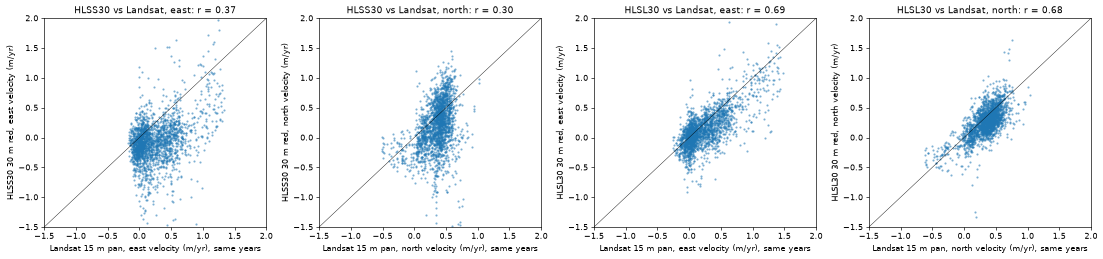

In [16]:
# WHAT THIS DOES: runs the full tracking chain on each HLS stack and compares the result with Landsat.
def hls_masks():
    """Masks on the 30 m HLS grid: re-rasterise OSM / hand-drawn polygons, take NDVI/WorldCover from the 15 m grid."""
    rows_, cols_ = np.mgrid[0:GH.height, 0:GH.width]
    x_, y_ = GH.xy(rows_, cols_)
    r15, c15 = GRID.rowcol(x_, y_)
    r15 = np.clip(np.round(r15).astype(int), 0, GRID.height - 1); c15 = np.clip(np.round(c15).astype(int), 0, GRID.width - 1)
    auto = (VEG | WCM)[r15, c15] | masks.osm_mask(OSM, GH)[0]
    man = masks.manual_mask(SITE_CFG / "manual_masks.geojson", GH)[0]
    return auto, man, rasters.box_mask(GH, SITE["bbox"])
AUTO_H, MAN_H, INBOX_H = hls_masks()
def run_hls(product):
    picks = HPICK[HPICK["product"] == product].reset_index(drop=True)
    imgs, tt, el_ = [], [], []
    for _, r in picks.iterrows():
        a_, _ = rasters.read(HDIR / f"{product}_{r['id']}.tif")
        b4 = a_[0].astype(np.float32)
        bad = ndimage.binary_dilation((a_[1].astype(np.int32) & 0b1110) != 0, iterations=1) | (b4 <= 0) | (b4 == -9999)
        b4[bad] = np.nan; imgs.append(b4)
        d_ = pd.Timestamp(r["date"]); tt.append(d_.year + (d_.day_of_year - 1) / (366 if d_.is_leap_year else 365)); el_.append(90 - r["mean_sun_zenith"])
    tt = np.array(tt); el_ = np.array(el_)
    Rh, Ch = tk.window_centres((GH.height, GH.width), P["hls_win"], P["hls_step"], margin=P["hls_win"] // 2)
    rh, ch = Rh.ravel(), Ch.ravel()
    ep = list(range(len(imgs)))
    prs = [(a, b) for k, a in enumerate(ep) for b in ep[k + 1:]]
    Dh = motion.track_all(imgs, prs, rh, ch, P["hls_win"], upsample=P["upsample"])
    nul = motion.null_peaks(imgs, prs[::7], rh, ch, P["hls_win"], 20, upsample=P["upsample"])
    pmin = float(np.percentile(nul, P["null_pctl"]))
    maxd = P["max_disp_px"] * P["hls_win"] / P["win"]
    fa, fm = tk.window_stat(AUTO_H, rh, ch, P["hls_win"]), tk.window_stat(MAN_H, rh, ch, P["hls_win"])
    fnd = tk.window_stat(AUTO_H | MAN_H, rh, ch, P["hls_win"])
    mp, fv = motion.coherence(Dh, prs, pmin, maxd)
    stab = np.where((fa >= P["stable_min_frac"]) & (fm == 0) & (mp >= P["stable_min_med_peak"]) & (fv >= P["stable_min_valid"]))[0]
    offs_ = motion.pair_offsets(Dh, prs, stab, pmin, maxd, 30.0)
    gE, gN, *_ = motion.epoch_registration(offs_, len(imgs))
    cinh = INBOX_H[rh, ch]
    dun = np.where(cinh & (fnd <= P["dune_max_nondune"]))[0]
    # dune windows on masked images, as for Landsat
    ndm = ndimage.binary_dilation(AUTO_H | MAN_H, iterations=1)
    imgs_d = [np.where(ndm, np.nan, im) for im in imgs]
    Dd = motion.track_all(imgs_d, prs, rh[dun], ch[dun], P["hls_win"], upsample=P["upsample"], max_nan_frac=MAXNAN_D)
    pmin_d = float(np.percentile(motion.null_peaks(imgs_d, prs[::7], rh[dun], ch[dun], P["hls_win"], 20, upsample=P["upsample"], max_nan_frac=MAXNAN_D), P["null_pctl"]))
    yE, yN, vv = motion.observations(Dd, prs, np.arange(dun.size), gE, gN, pmin_d, maxd, 30.0)
    vel = motion.velocities(yE, yN, vv, prs, tt, ep)
    nt = motion.held_out_null(Dh, prs, prs, ep, stab, tt, len(imgs), pmin, maxd, 30.0, seed=P["seed"])
    se0 = (nt["sE"] + nt["sN"]) / 2
    fcal = float(np.nanpercentile(np.hypot(nt["vE"], nt["vN"]) / (motion.CHI2_2DOF_95 * se0), 95))
    ssys = float(np.hypot(nt["reg_velocity_diff_E"], nt["reg_velocity_diff_N"]) / np.sqrt(2))
    sig_ = np.sqrt((fcal * (vel["sE"] + vel["sN"]) / 2) ** 2 + ssys ** 2)
    sp_ = np.hypot(vel["vE"], vel["vN"])
    val = (vel["n_used"] >= P["dune_min_valid"] * len(prs)) & np.isfinite(sp_)
    det_ = val & (sp_ > motion.CHI2_2DOF_95 * sig_)
    resid = []
    for (i, j) in prs:
        ok = np.zeros(rh.size, bool); ok[stab] = True; ok &= motion.valid_obs(Dh[(i, j)], pmin, maxd)
        resid.append(np.hypot(Dh[(i, j)][1][ok] * 30 - (gE[j] - gE[i]), -Dh[(i, j)][0][ok] * 30 - (gN[j] - gN[i])))
    resid = np.concatenate(resid)
    return dict(product=product, picks=picks, t=tt, el=el_, rh=rh, ch=ch, dun=dun, vel=vel, val=val, det=det_, sig=sig_, speed=sp_,
                peak_min=pmin, n_stable=len(stab), fcal=fcal, dl=float(np.nanmedian(motion.CHI2_2DOF_95 * sig_[val])),
                heldout_stable_median=[float(np.nanmedian(nt["vE"])), float(np.nanmedian(nt["vN"]))], reg_sys=ssys,
                stable_resid_nmad_m=float(1.4826 * np.median(np.abs(resid - np.median(resid)))), stable_resid_p95_m=float(np.percentile(resid, 95)))

def landsat_on_hls(H, years=None):
    """Average Landsat dune-window velocities (optionally refitted on a sub-period) inside each HLS window footprint."""
    if years is None:
        vE_, vN_ = VEL["vE"], VEL["vN"]
    else:
        keep = [k for k, g in enumerate(OLI) if years[0] <= T[g] <= years[1] + 1]
        vE_, _, _, _, _, _ = nw.line_fit(VEL["t"][keep], VEL["PE"][:, keep]); vN_, _, _, _, _, _ = nw.line_fit(VEL["t"][keep], VEL["PN"][:, keep])
    xl, yl = GRID.xy(rr[DUNE_IDX], cc[DUNE_IDX])
    xh, yh = GH.xy(H["rh"][H["dun"]], H["ch"][H["dun"]])
    half = P["hls_win"] * 30.0 / 2
    out = np.full((H["dun"].size, 2), np.nan)
    okl = d_valid & np.isfinite(vE_)
    for k in range(H["dun"].size):
        m_ = okl & (np.abs(xl - xh[k]) <= half) & (np.abs(yl - yh[k]) <= half)
        if m_.sum() >= 3:
            out[k] = [np.mean(vE_[m_]), np.mean(vN_[m_])]
    return out

HLS = {}
for prod in ["HLSS30", "HLSL30"]:
    if (HPICK["product"] == prod).sum() < 4:
        print(f"{prod}: fewer than 4 usable years, skipped"); continue
    t0 = time.time()
    H = run_hls(prod)
    yrs = (H["t"].min(), H["t"].max())
    L_ = landsat_on_hls(H, years=yrs)
    both = H["val"] & np.isfinite(L_[:, 0])
    vh = np.column_stack([H["vel"]["vE"], H["vel"]["vN"]])
    rE_ = float(np.corrcoef(vh[both, 0], L_[both, 0])[0, 1]); rN_ = float(np.corrcoef(vh[both, 1], L_[both, 1])[0, 1])
    dif = vh[both] - L_[both]
    fmH, fmL = np.median(vh[both], axis=0), np.median(L_[both], axis=0)
    strong = both & (np.hypot(L_[:, 0], L_[:, 1]) > 2 * DL_FIELD)
    H["strong"] = dict(n=int(strong.sum()),
                       corr_E=round(float(np.corrcoef(vh[strong, 0], L_[strong, 0])[0, 1]), 3) if strong.sum() > 10 else None,
                       corr_N=round(float(np.corrcoef(vh[strong, 1], L_[strong, 1])[0, 1]), 3) if strong.sum() > 10 else None,
                       median_speed_hls=round(float(np.median(np.hypot(vh[strong, 0], vh[strong, 1]))), 3) if strong.sum() else None,
                       median_speed_landsat=round(float(np.median(np.hypot(L_[strong, 0], L_[strong, 1]))), 3) if strong.sum() else None,
                       median_heading_diff_deg=round(float(np.median(wind.angle_diff(tk.heading_deg(vh[strong, 0], vh[strong, 1]), tk.heading_deg(L_[strong, 0], L_[strong, 1])))), 1) if strong.sum() else None)
    H["cmp"] = dict(years=f"{H['picks'].date.min():%Y-%m-%d} to {H['picks'].date.max():%Y-%m-%d}", n_scenes=len(H["picks"]),
                    n_windows_compared=int(both.sum()), corr_E=round(rE_, 3), corr_N=round(rN_, 3),
                    median_diff_E_myr=round(float(np.median(dif[:, 0])), 3), median_diff_N_myr=round(float(np.median(dif[:, 1])), 3),
                    rms_diff_myr=round(float(np.sqrt(np.mean(np.sum(dif ** 2, axis=1)))), 3),
                    field_median_velocity_hls_E_N=[round(float(x), 3) for x in fmH], field_median_velocity_landsat_E_N=[round(float(x), 3) for x in fmL],
                    field_median_speed_hls_myr=round(float(np.hypot(*fmH)), 3), field_median_speed_landsat_myr=round(float(np.hypot(*fmL)), 3),
                    field_median_heading_hls_deg=round(float(tk.heading_deg(*fmH)), 1), field_median_heading_landsat_deg=round(float(tk.heading_deg(*fmL)), 1),
                    heading_difference_deg=round(float(wind.angle_diff(tk.heading_deg(*fmH), tk.heading_deg(*fmL))), 1),
                    hls_detection_limit_median_myr=round(H["dl"], 3), hls_pct_valid_windows_detected=round(100 * float(H["det"].sum() / max(H["val"].sum(), 1)), 1),
                    hls_stable_residual_nmad_m=round(H["stable_resid_nmad_m"], 2), hls_stable_residual_p95_m=round(H["stable_resid_p95_m"], 2),
                    hls_peak_threshold=round(H["peak_min"], 3), hls_n_stable_windows=H["n_stable"], hls_error_inflation=round(H["fcal"], 2),
                    hls_heldout_stable_median_velocity_E_N=[round(x, 3) for x in H["heldout_stable_median"]], hls_registration_systematic_myr=round(H["reg_sys"], 4),
                    landsat_detected_share_in_compared_windows=round(float(np.mean(np.hypot(*L_[both].T) > DL_FIELD)), 3),
                    windows_where_landsat_speed_gt_2x_detection_limit=H["strong"])
    HLS[prod] = H
    print(f"{prod} ({time.time() - t0:.0f} s):", json.dumps(H["cmp"], indent=1))

fig, axes = plt.subplots(1, 2 * len(HLS), figsize=(6 * len(HLS) * 2 / 1.3, 4.4))
axes = np.atleast_1d(axes)
for k, (prod, H) in enumerate(HLS.items()):
    L_ = landsat_on_hls(H, years=(H["t"].min(), H["t"].max()))
    both = H["val"] & np.isfinite(L_[:, 0])
    for c_, comp in enumerate(["east", "north"]):
        a = axes[2 * k + c_]
        a.scatter(L_[both, c_], [H["vel"]["vE"], H["vel"]["vN"]][c_][both], s=3, alpha=0.4)
        a.plot([-2, 2], [-2, 2], "k-", lw=0.5); a.set_xlim(-1.5, 2); a.set_ylim(-1.5, 2)
        a.set_xlabel(f"Landsat 15 m pan, {comp} velocity (m/yr), same years"); a.set_ylabel(f"{prod} 30 m red, {comp} velocity (m/yr)")
        a.set_title(f"{prod} vs Landsat, {comp}: r = {H['cmp']['corr_E' if c_ == 0 else 'corr_N']:.2f}")
plt.tight_layout(); plt.savefig(OUT / "02_hls_comparison.png"); plt.show()
QC["hls_second_dataset"] = {p_: {**H["cmp"], "independence": ("independent satellite and sensor (Sentinel-2 MSI), independent geolocation (AROP_NCP = 0), red band at 30 m; shares place, season, masks and code"
                                                             if p_ == "HLSS30" else "NOT independent: same Landsat 8/9 OLI instruments as the primary data; tests band (red vs pan), 30 m resolution and HLS processing only")}
                            for p_, H in HLS.items()}

## 13 · Physical sanity checks

- **Speeds** are compared with what dunes of this size do. Published barchan speeds are a few to a few tens of m/yr in high-energy deserts; this site's wind is **low energy** (notebook 01: DP ≈ 66 VU/yr, "low"), so sub-metre speeds are physically plausible here, and anything above ~10 m/yr would be suspect.
- **Heading versus wind**: the field's directions are compared with the resultant drift direction (RDD) from notebook 01. The wind regime is **bimodal** (RDP/DP ≈ 0.38: north-westerly afternoon winds pushing sand to the south-east, southerly morning winds pushing it north), so the resultant is a small difference of two large opposing vectors and dunes may follow either mode, or their combination, rather than the resultant.

detected windows: 1394; field-median velocity vector +0.261 E, +0.474 N m/yr -> heading 29 deg, speed 0.54 m/yr
speed-weighted mean heading 39 deg, circular SD 48 deg; heading quartiles [ 32.  76. 330.]
wind: RDD 99.9 deg (resultant, sand moves toward), RDP/DP 0.38; strongest sand-rose sector blows toward 135 deg, the strongest opposing one toward 0 deg
|field heading - RDD| = 71 deg; |field heading - 135| = 106 deg; |field heading - 0| = 29 deg
per-window |heading - RDD|: median 74 deg; share within 45 deg of RDD 31 %, of 135 deg 12 %, of 0 deg 63 %
speeds above 10 m/yr: 0; above 3 m/yr: 0


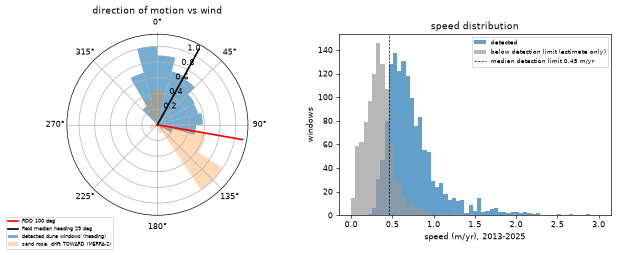

In [17]:
# WHAT THIS DOES: speed plausibility, and heading of the detected windows against the wind's resultant drift direction
# and the two main sand-moving wind modes.
WS = json.loads((PUB / "wind_summary.json").read_text())
RDD = float(WS["RDD_deg"])
rose = pd.DataFrame(WS["sand_rose"]); rose["to_deg"] = (rose.sector_deg + 180) % 360
top2 = rose.sort_values("dp", ascending=False)
mode1 = float(top2.iloc[0].to_deg)
mode2 = float(next(r.to_deg for _, r in top2.iterrows() if wind.angle_diff(r.to_deg, mode1) > 90))
hd = HEAD[DET]
fmE_, fmN_ = np.median(VEL["vE"][DET]), np.median(VEL["vN"][DET])
FIELD_HEAD = float(tk.heading_deg(fmE_, fmN_))
# speed-weighted mean direction and circular spread
C_, S_ = np.average(np.cos(np.radians(hd)), weights=SPEED[DET]), np.average(np.sin(np.radians(hd)), weights=SPEED[DET])
MEAN_HEAD = float(np.degrees(np.arctan2(S_, C_)) % 360); R_ = float(np.hypot(C_, S_))
circ_sd = float(np.degrees(np.sqrt(-2 * np.log(R_))))
agree = wind.angle_diff(hd, RDD)
print(f"detected windows: {DET.sum()}; field-median velocity vector {fmE_:+.3f} E, {fmN_:+.3f} N m/yr -> heading {FIELD_HEAD:.0f} deg, speed {np.hypot(fmE_, fmN_):.2f} m/yr")
print(f"speed-weighted mean heading {MEAN_HEAD:.0f} deg, circular SD {circ_sd:.0f} deg; heading quartiles {np.percentile(hd, [25, 50, 75]).round(0)}")
print(f"wind: RDD {RDD:.1f} deg (resultant, sand moves toward), RDP/DP {WS['RDP_DP']:.2f}; strongest sand-rose sector blows toward {mode1:.0f} deg, the strongest opposing one toward {mode2:.0f} deg")
print(f"|field heading - RDD| = {wind.angle_diff(FIELD_HEAD, RDD):.0f} deg; |field heading - {mode1:.0f}| = {wind.angle_diff(FIELD_HEAD, mode1):.0f} deg; |field heading - {mode2:.0f}| = {wind.angle_diff(FIELD_HEAD, mode2):.0f} deg")
print(f"per-window |heading - RDD|: median {np.median(agree):.0f} deg; share within 45 deg of RDD {100 * np.mean(agree <= 45):.0f} %, of {mode1:.0f} deg {100 * np.mean(wind.angle_diff(hd, mode1) <= 45):.0f} %, of {mode2:.0f} deg {100 * np.mean(wind.angle_diff(hd, mode2) <= 45):.0f} %")
print(f"speeds above 10 m/yr: {(SPEED[DET] > 10).sum()}; above 3 m/yr: {(SPEED[DET] > 3).sum()}")
fig = plt.figure(figsize=(11, 4.4))
a = fig.add_subplot(1, 2, 1, projection="polar"); a.set_theta_zero_location("N"); a.set_theta_direction(-1)
hb = np.histogram(hd, bins=np.arange(0, 361, 15))[0]
a.bar(np.radians(np.arange(7.5, 360, 15)), hb / hb.max(), width=np.radians(15), alpha=0.6, label="detected dune windows (heading)")
rb = rose.sort_values("to_deg")
a.bar(np.radians(rb.to_deg), rb.dp / rb.dp.max(), width=np.radians(22.5), alpha=0.3, color="C1", label="sand rose, drift TOWARD (MERRA-2)")
a.plot([np.radians(RDD)] * 2, [0, 1.1], "r-", lw=2, label=f"RDD {RDD:.0f} deg")
a.plot([np.radians(FIELD_HEAD)] * 2, [0, 1.1], "k-", lw=2, label=f"field median heading {FIELD_HEAD:.0f} deg")
a.legend(fontsize=6, loc="lower left", bbox_to_anchor=(-0.35, -0.2)); a.set_title("direction of motion vs wind")
a = fig.add_subplot(1, 2, 2)
a.hist(SPEED[DET], bins=np.linspace(0, max(3, np.percentile(SPEED[DET], 99.5)), 60), color="C0", alpha=0.7, label="detected")
a.hist(SPEED[d_valid & ~DET], bins=np.linspace(0, max(3, np.percentile(SPEED[DET], 99.5)), 60), color="0.6", alpha=0.7, label="below detection limit (estimate only)")
a.axvline(DL_FIELD, color="k", ls="--", lw=0.8, label=f"median detection limit {DL_FIELD:.2f} m/yr")
a.set_xlabel("speed (m/yr), 2013-2025"); a.set_ylabel("windows"); a.legend(fontsize=7); a.set_title("speed distribution")
plt.tight_layout(); plt.savefig(OUT / "02_wind_and_speed.png"); plt.show()
QC["physics"] = {"wind_RDD_deg": RDD, "wind_RDP_DP": WS["RDP_DP"], "wind_mode_toward_deg": [mode1, mode2],
                 "field_median_velocity_E_N_myr": [round(float(fmE_), 3), round(float(fmN_), 3)], "field_median_heading_deg": round(FIELD_HEAD, 1),
                 "speed_weighted_mean_heading_deg": round(MEAN_HEAD, 1), "heading_circular_sd_deg": round(circ_sd, 1),
                 "field_heading_minus_RDD_deg": round(float(wind.angle_diff(FIELD_HEAD, RDD)), 1),
                 "field_heading_minus_modes_deg": [round(float(wind.angle_diff(FIELD_HEAD, mode1)), 1), round(float(wind.angle_diff(FIELD_HEAD, mode2)), 1)],
                 "per_window_abs_heading_minus_RDD_median_deg": round(float(np.median(agree)), 1),
                 "share_within_45deg_of_RDD_pct": round(100 * float(np.mean(agree <= 45)), 1),
                 "detected_speed_median_myr": round(float(np.median(SPEED[DET])), 3), "detected_speed_p10_p90_myr": [round(float(np.percentile(SPEED[DET], 10)), 3), round(float(np.percentile(SPEED[DET], 90)), 3)],
                 "detected_speed_max_myr": round(float(SPEED[DET].max()), 3), "n_detected_gt_3myr": int((SPEED[DET] > 3).sum()), "n_detected_gt_10myr": int((SPEED[DET] > 10).sum())}

## 14 · Does NASADEM resolve these dunes?

NASADEM is SRTM C-band radar from **11-22 February 2000**, 1 arc-second (~30 m), with metre-level vertical noise. Two tests decide what it can outline:
1. **Noise**: the high-passed DEM over the smoothest ground in the box (lowest 10 % of image texture, not vegetated) gives the DEM noise σz; only crests standing at least 3 σz above their surroundings are candidates.
2. **Shape check against the image**: the DEM is shaded with the sun of the earliest confirmed scene (the closest in time to February 2000) and correlated, locally (270 m windows), with that image. Where NASADEM really has the dune, its shading pattern matches the image. A candidate counts as **resolved** only if its local correlation exceeds the 95th percentile of the same statistic computed against an unrelated (shifted) image.

Only resolved dunes are outlined and get a NASADEM height. Smaller dunes are not outlined: their motion is still in the velocity field (`vectors.geojson`), but no height is invented for them.

In [18]:
# WHAT THIS DOES: estimates NASADEM noise, finds crest candidates, segments them, and keeps the dunes whose DEM
# shading agrees with the image.
z = rasters.read(RAW / "dem" / "nasadem_elevation_30m_bilinear.tif")[0][0].astype(float)
z_s = ndimage.gaussian_filter(z, P["dem_smooth_px"])
E0 = conf_idx[0]
p30 = np.nan_to_num(IMGS[E0], nan=np.nanmedian(IMGS[E0])).reshape(G30.height, 2, G30.width, 2).mean(axis=(1, 3))
def coarse(m):
    return m.reshape(G30.height, 2, G30.width, 2).mean(axis=(1, 3))
INBOX30, ND30, VEG30 = coarse(INBOX.astype(float)) > 0.5, coarse(NONDUNE.astype(float)), coarse(VEG.astype(float)) > 0
tex30 = ndimage.generic_filter(p30, np.std, size=5)
smooth = INBOX30 & ~VEG30 & (tex30 <= np.percentile(tex30[INBOX30], 10))
hpz = z - ndimage.gaussian_filter(z, 1.5)
SIGMA_Z = float(np.std(hpz[smooth]))
dune_area30 = INBOX30 & (ND30 <= 0.5)
print(f"NASADEM noise (std of the 45 m high-pass over the smoothest 10 % of the box, {smooth.sum()} px): {SIGMA_Z:.2f} m; "
      f"same statistic over the dune area: {np.std(hpz[dune_area30]):.2f} m")
H_MIN = P["dem_k_sigma"] * SIGMA_Z
shade = dn.hillshade(z_s, SC.sun_az[E0], SC.sun_el[E0], 30.0)
LC = dn.local_corr(dn.highpass(shade, 6), dn.highpass(p30, 6), P["dem_corr_px"])
LC_NULL = dn.local_corr(dn.highpass(shade, 6), np.roll(dn.highpass(p30, 6), (37, 53), axis=(0, 1)), P["dem_corr_px"])
LC_THR = float(np.percentile(LC_NULL[dune_area30], 95))
print(f"DEM-shading vs {SC.date[E0]} image, local correlation over the dune area: median {np.median(LC[dune_area30]):.2f}; "
      f"null (unrelated image) median {np.median(LC_NULL[dune_area30]):.2f}, 95th pct {LC_THR:.2f}")
BASE = dn.base_surface(z_s, P["dem_base_radius_m"] / 30.0)
RELIEF = z_s - BASE
LAB, INFO = dn.segment(z_s, dune_area30, H_MIN, base=BASE, min_px=P["dem_min_px"])
for d_ in INFO:
    m_ = LAB == d_["label"]
    d_["dem_image_corr"] = float(np.mean(LC[ndimage.binary_dilation(m_, iterations=1)]))
    d_["resolved"] = bool(d_["dem_image_corr"] >= LC_THR and d_["height_m"] >= H_MIN)
DI = pd.DataFrame(INFO)
print(f"crest candidates with prominence >= {H_MIN:.1f} m (3 sigma_z): {len(DI)}; resolved (DEM shape matches the image): {DI.resolved.sum()}")
if DI.resolved.any():
    R_ = DI[DI.resolved]
    print(f"resolved dunes: height {R_.height_m.min():.1f}-{R_.height_m.max():.1f} m (median {R_.height_m.median():.1f}), "
          f"outline area {R_.n_px.min() * 900 / 1e4:.1f}-{R_.n_px.max() * 900 / 1e4:.1f} ha")
    print(f"unresolved candidates: median height {DI[~DI.resolved].height_m.median():.1f} m, median area {DI[~DI.resolved].n_px.median() * 900 / 1e4:.1f} ha")
for hh in [2, 4, 6, 8, 10, 15]:
    sub = DI[DI.height_m >= hh]
    if len(sub):
        print(f"  candidates with height >= {hh:>2} m: {len(sub):4d}, resolved {100 * sub.resolved.mean():5.1f} %")
QC["nasadem"] = {"date": "2000-02-11/22 (SRTM)", "noise_sigma_m": round(SIGMA_Z, 2), "h_min_m": round(H_MIN, 2),
                 "dune_area_highpass_std_m": round(float(np.std(hpz[dune_area30])), 2),
                 "shading_corr_median_dune_area": round(float(np.median(LC[dune_area30])), 3), "shading_corr_null_p95": round(LC_THR, 3),
                 "n_candidates": int(len(DI)), "n_resolved": int(DI.resolved.sum()) if len(DI) else 0,
                 "resolved_share_by_min_height": {str(hh): round(float(DI[DI.height_m >= hh].resolved.mean()), 3) for hh in [2, 4, 6, 8, 10, 15] if (DI.height_m >= hh).any()}}

NASADEM noise (std of the 45 m high-pass over the smoothest 10 % of the box, 11051 px): 1.95 m; same statistic over the dune area: 3.15 m
DEM-shading vs 2000-11-27 image, local correlation over the dune area: median 0.16; null (unrelated image) median -0.00, 95th pct 0.37


crest candidates with prominence >= 5.8 m (3 sigma_z): 124; resolved (DEM shape matches the image): 21
resolved dunes: height 14.0-71.6 m (median 25.5), outline area 2.0-13.3 ha
unresolved candidates: median height 17.7 m, median area 4.0 ha
  candidates with height >=  2 m:  124, resolved  16.9 %
  candidates with height >=  4 m:  124, resolved  16.9 %
  candidates with height >=  6 m:  124, resolved  16.9 %
  candidates with height >=  8 m:  124, resolved  16.9 %
  candidates with height >= 10 m:  124, resolved  16.9 %
  candidates with height >= 15 m:   95, resolved  20.0 %


## 15 · Dunes: outlines, motion, classes

For every resolved dune: the Landsat dune windows whose centres lie within 120 m of its outline give its motion (vector median of their velocities). **Scale caveat:** the windows (480 m) are larger than most outlines (2-13 ha), so this is the motion of the sand surface on and around the dune, including smaller dunes riding over it; for a dune tens of metres high, c ≈ Q/H says the body itself should move far more slowly than the small dunes around it. `implied_flux_m2_per_yr` (speed × height) is written so this can be judged per dune. Its uncertainty is the median calibrated σ of those windows (the windows overlap, so they are not averaged down), and motion is **detected** only above 2.45 σ. Below that the dune is reported as `below_detection_limit`, with `speed_med_myr = 0`, `speed_lo_myr = 0`, `speed_hi_myr` = its detection limit (the honest statement is "somewhere between 0 and the detection limit"), and no heading.

- **2025 position**: the February-2000 outline moved by its velocity × the time to the latest confirmed scene; not moved if motion is below the detection limit.
- **Height model** (`speed = k / height`, c ≈ Q/H): fitted on dunes with detected motion; used to fill dunes without tracking only if the fit is supported (at least 8 dunes and a significant negative rank correlation between speed and height). Otherwise not used, and untracked dunes are left out.
- **Classes**: `stable` = below the detection limit; for detected dunes, cut-offs at the median and 90th percentile of all detected window speeds (rounded to 0.05 m/yr) separate `slow`, `active` and `fast`. These are *relative to this field*: "fast" here is about a metre per year, not the ~10 m/yr of a high-energy barchan field.
- **Confidence**: `high` = ≥ 4 windows with median match quality ≥ 0.4; `medium` = ≥ 2 windows; `low` = otherwise.
- **Threat fields** (`threat`, `nearest_target`, `distance_to_target_m`, `reach_year_min/max`) belong to notebook 03 and are written as false/null here, with `threat_status = "not computed (notebook 03)"`.

In [19]:
# WHAT THIS DOES: per-dune motion statistics, height model test, classes, and the two dune GeoJSON files.
from shapely.geometry import Point, mapping
from shapely import affinity
to_ll = Transformer.from_crs(GRID.crs, "EPSG:4326", always_xy=True).transform
polys = dn.polygons(LAB, G30)
xw, yw = GRID.xy(rr[DUNE_IDX], cc[DUNE_IDX])
T_DEM = 2000.0 + 46.0 / 365.0          # mid-February 2000 (SRTM 11-22 Feb)
T_NOW = float(T[LATEST])
det_speeds = SPEED[DET]
CUT1, CUT2 = [float(np.round(np.percentile(det_speeds, q) / 0.05) * 0.05) for q in (50, 90)]
print(f"class cut-offs from the detected window speeds: stable = below detection limit; slow < {CUT1:.2f} <= active < {CUT2:.2f} <= fast (m/yr)")
rows_d = []
for d_ in INFO:
    if not d_["resolved"]:
        continue
    g = polys[d_["label"]]
    near = np.array([g.distance(Point(x_, y_)) <= 120.0 for x_, y_ in zip(xw, yw)])
    w_ = near & d_valid
    rec = dict(label=d_["label"], height_m=d_["height_m"], area_km2=g.area / 1e6, dem_image_corr=d_["dem_image_corr"], n_windows=int(w_.sum()))
    if w_.sum():
        vE_, vN_ = float(np.median(VEL["vE"][w_])), float(np.median(VEL["vN"][w_]))
        s_ = float(np.median(SIG[w_]))
        rec.update(vE=vE_, vN=vN_, speed=float(np.hypot(vE_, vN_)), sigma=s_, dl=motion.CHI2_2DOF_95 * s_,
                   quality=float(np.median(QUAL[w_])), det_share=float(DET[w_].mean()))
        rec["detected"] = rec["speed"] > rec["dl"]
    rows_d.append(rec)
DD = pd.DataFrame(rows_d)
print(f"resolved dunes: {len(DD)}; with tracking windows: {(DD.n_windows > 0).sum()}; motion detected: {int(DD.get('detected', pd.Series(dtype=bool)).fillna(False).sum())}")

# speed vs height (c ~ Q/H) on dunes with detected motion
hm = DD[(DD.n_windows > 0) & (DD.detected == True)]
HEIGHT_MODEL = {"n_dunes": int(len(hm)), "used": False}
if len(hm) >= 3:
    rho, p_rho = stats.spearmanr(hm.height_m, hm.speed)
    k_fit = float(np.sum(hm.speed / hm.height_m) / np.sum(1 / hm.height_m ** 2))   # least squares for speed = k / H
    HEIGHT_MODEL.update(spearman_rho=round(float(rho), 3), p_value=round(float(p_rho), 4), k_m2_per_yr=round(k_fit, 2),
                        flux_equivalent_note="k = speed x height ~ bulk sand flux per unit crest length (m^2/yr)")
    HEIGHT_MODEL["used"] = bool(len(hm) >= 8 and rho < 0 and p_rho < 0.05)
    print(f"speed vs height on {len(hm)} dunes with detected motion: Spearman rho = {rho:.2f} (p = {p_rho:.3f}); "
          f"speed x height = {np.median(hm.speed * hm.height_m):.1f} m^2/yr (median), k fit {k_fit:.1f}; height model used: {HEIGHT_MODEL['used']}")
# the same physics at window level, where every window has a NASADEM relief (95th pct of DEM minus local base inside the
# 480 m window): do windows with more relief (bigger dunes) move more slowly? Uses all valid windows' speed estimates.
r30, c30 = rr[DUNE_IDX] // 2, cc[DUNE_IDX] // 2
half30 = P["win"] // 4
win_relief = np.array([np.percentile(RELIEF[max(0, a_ - half30):a_ + half30, max(0, b_ - half30):b_ + half30], 95) for a_, b_ in zip(r30, c30)])
okr = d_valid & np.isfinite(win_relief)
rho_w, p_w_ = stats.spearmanr(win_relief[okr], SPEED[okr])
terc = np.percentile(win_relief[okr], [33.3, 66.7])
tb = np.digitize(win_relief[okr], terc)
terc_tab = [dict(relief_m=f"{lo_:.1f}-{hi_:.1f}", n=int((tb == k_).sum()), median_speed_myr=round(float(np.median(SPEED[okr][tb == k_])), 3),
                 share_detected=round(float(DET[okr][tb == k_].mean()), 3))
            for k_, (lo_, hi_) in enumerate(zip([win_relief[okr].min(), *terc], [*terc, win_relief[okr].max()]))]
print(f"window level ({okr.sum()} windows): Spearman rho(speed, NASADEM relief) = {rho_w:.2f} (p = {p_w_:.1e}); by relief tercile: {terc_tab}")
HEIGHT_MODEL["window_level"] = {"spearman_rho": round(float(rho_w), 3), "p_value": float(p_w_), "terciles": terc_tab,
                                "note": f"relief = 95th percentile of (NASADEM - local base) in each 480 m window; NASADEM noise {SIGMA_Z:.1f} m, so low-relief terciles are partly noise"}
untracked = DD[DD.n_windows == 0]
print(f"resolved dunes without any valid tracking window: {len(untracked)} -> "
      + ("filled with the height model" if HEIGHT_MODEL["used"] else "left out of dunes.geojson (no justified gap fill)"))

def to_wgs(g):
    return rasters.reproject_geom(to_ll, g)
def rnd(geom):
    m_ = mapping(geom)
    return {"type": m_["type"], "coordinates": [[[round(x_, 6), round(y_, 6)] for x_, y_ in ring] for ring in m_["coordinates"]]}
feats, feats0, table = [], [], []
k = 0
for _, r in DD.sort_values(["height_m"], ascending=False).iterrows():
    if r.n_windows == 0 and not HEIGHT_MODEL["used"]:
        continue
    k += 1
    did = f"D{k:03d}"
    g0 = polys[int(r.label)]
    if r.n_windows > 0:
        src = "tracked"
        detected = bool(r.detected)
        sp_, sg_, dl_ = float(r.speed), float(r.sigma), float(r.dl)
        vE_, vN_ = float(r.vE), float(r.vN)
    else:
        src = "height_model"
        sp_ = HEIGHT_MODEL["k_m2_per_yr"] / r.height_m; sg_ = float(np.median(hm.speed.std() if len(hm) > 1 else sp_)); dl_ = motion.CHI2_2DOF_95 * sg_
        detected = True; vE_ = sp_ * np.sin(np.radians(FIELD_HEAD)); vN_ = sp_ * np.cos(np.radians(FIELD_HEAD))
    if detected:
        cls = "slow" if sp_ < CUT1 else ("active" if sp_ < CUT2 else "fast")
        head = float(tk.heading_deg(vE_, vN_))
        med, lo, hi = sp_, max(0.0, sp_ - sg_), sp_ + sg_
        g1 = affinity.translate(g0, xoff=vE_ * (T_NOW - T_DEM), yoff=vN_ * (T_NOW - T_DEM))
    else:
        cls, head, med, lo, hi, g1 = "stable", None, 0.0, 0.0, dl_, g0
    conf_ = "high" if (r.n_windows >= 4 and r.get("quality", 0) >= 0.4) else ("medium" if r.n_windows >= 2 else "low")
    props = {"id": did, "height_m": round(float(r.height_m), 1), "area_km2": round(float(r.area_km2), 4),
             "speed_med_myr": round(med, 2), "speed_lo_myr": round(lo, 2), "speed_hi_myr": round(hi, 2),
             "heading_deg": None if head is None else round(head, 1), "uncertainty_myr": round(sg_, 2), "confidence": conf_,
             "speed_source": src, "class": cls, "threat": False, "nearest_target": None, "distance_to_target_m": None,
             "reach_year_min": None, "reach_year_max": None,
             "wind_agreement_deg": None if head is None else round(float(wind.angle_diff(head, RDD)), 1),
             "below_detection_limit": not detected, "detection_limit_myr": round(dl_, 2),
             "speed_estimate_myr": round(sp_, 2), "n_windows": int(r.n_windows),
             "implied_flux_m2_per_yr": round(med * float(r.height_m), 1) if detected else None,
             "motion_scale_note": "motion measured in 480 m windows within 120 m of the outline: it includes the sand surface and smaller dunes on and around this dune, not only the dune body",
             "height_source": "NASADEM (SRTM, Feb 2000), crest minus local base", "outline_source": "NASADEM watershed, upper half of the dune body",
             "dem_image_corr": round(float(r.dem_image_corr), 3), "position_date": SC.date[LATEST],
             "threat_status": "not computed (notebook 03)"}
    feats.append({"type": "Feature", "properties": props, "geometry": rnd(to_wgs(g1))})
    feats0.append({"type": "Feature", "properties": {"id": did, "year": 2000, "date": "2000-02 (SRTM/NASADEM)", "height_m": props["height_m"]},
                   "geometry": rnd(to_wgs(g0))})
    table.append({**{k_: v for k_, v in props.items() if k_ not in ("height_source", "outline_source", "threat_status")},
                  "vE_myr": round(vE_, 3), "vN_myr": round(vN_, 3)})
DUNES_T = pd.DataFrame(table)
DUNES_T.to_csv(OUT / "02_dunes_table.csv", index=False)
print(DUNES_T.drop(columns=["nearest_target", "distance_to_target_m", "reach_year_min", "reach_year_max", "threat"]).to_string(index=False) if len(DUNES_T) else "no dunes")
counts = DUNES_T["class"].value_counts().to_dict() if len(DUNES_T) else {}
print("counts by class:", counts)

note = (f"Dune outlines from NASADEM (SRTM, Feb 2000), kept only where NASADEM resolves the dune (DEM shading matches the {SC.date[E0]} Landsat image; "
        f"crest >= {H_MIN:.1f} m above its surroundings = 3 x DEM noise). Positions moved to {SC.date[LATEST]} by the measured Landsat 8/9 2013-{SC.date[LATEST][:4]} velocity. "
        f"Motion below the detection limit: below_detection_limit = true, speed_med_myr = 0, speed_lo_myr = 0, speed_hi_myr = detection limit, heading_deg = null, "
        f"wind_agreement_deg = null (no direction can be measured). Classes are relative to this field: stable = below detection limit, slow < {CUT1:.2f}, "
        f"active < {CUT2:.2f}, fast >= {CUT2:.2f} m/yr. Threat fields are not computed yet (notebook 03). Smaller dunes are not outlined; their motion is in vectors.geojson. "
        f"Computed by pipeline/02_tracking_and_dunes.ipynb.")
(PUB / "dunes.geojson").write_text(json.dumps({"type": "FeatureCollection", "note": note, "features": feats}, separators=(",", ":")) + "\n")
(PUB / "dunes_2000.geojson").write_text(json.dumps({"type": "FeatureCollection", "note": "Same dunes as dunes.geojson at their February 2000 (NASADEM) positions. " + note,
                                                    "features": feats0}, separators=(",", ":")) + "\n")
print(f"wrote {len(feats)} dunes -> {(PUB / 'dunes.geojson').relative_to(config.ROOT)} and dunes_2000.geojson")

class cut-offs from the detected window speeds: stable = below detection limit; slow < 0.65 <= active < 1.15 <= fast (m/yr)
resolved dunes: 21; with tracking windows: 21; motion detected: 6
speed vs height on 6 dunes with detected motion: Spearman rho = 0.60 (p = 0.208); speed x height = 15.8 m^2/yr (median), k fit 14.1; height model used: False


window level (2391 windows): Spearman rho(speed, NASADEM relief) = 0.15 (p = 1.3e-13); by relief tercile: [{'relief_m': '4.9-11.1', 'n': 796, 'median_speed_myr': 0.435, 'share_detected': 0.441}, {'relief_m': '11.1-15.0', 'n': 799, 'median_speed_myr': 0.588, 'share_detected': 0.675}, {'relief_m': '15.0-63.3', 'n': 796, 'median_speed_myr': 0.537, 'share_detected': 0.633}]
resolved dunes without any valid tracking window: 0 -> left out of dunes.geojson (no justified gap fill)
  id  height_m  area_km2  speed_med_myr  speed_lo_myr  speed_hi_myr  heading_deg  uncertainty_myr confidence speed_source  class  wind_agreement_deg  below_detection_limit  detection_limit_myr  speed_estimate_myr  n_windows  implied_flux_m2_per_yr                                                                                                                                            motion_scale_note  dem_image_corr position_date  vE_myr  vN_myr
D001      71.6    0.0603           0.00          0.00          0.51    

counts by class: {'stable': 15, 'active': 3, 'slow': 3}
wrote 21 dunes -> public/data/seih_al_hama/dunes.geojson and dunes_2000.geojson


wrote 337 vectors -> public/data/seih_al_hama/vectors.geojson


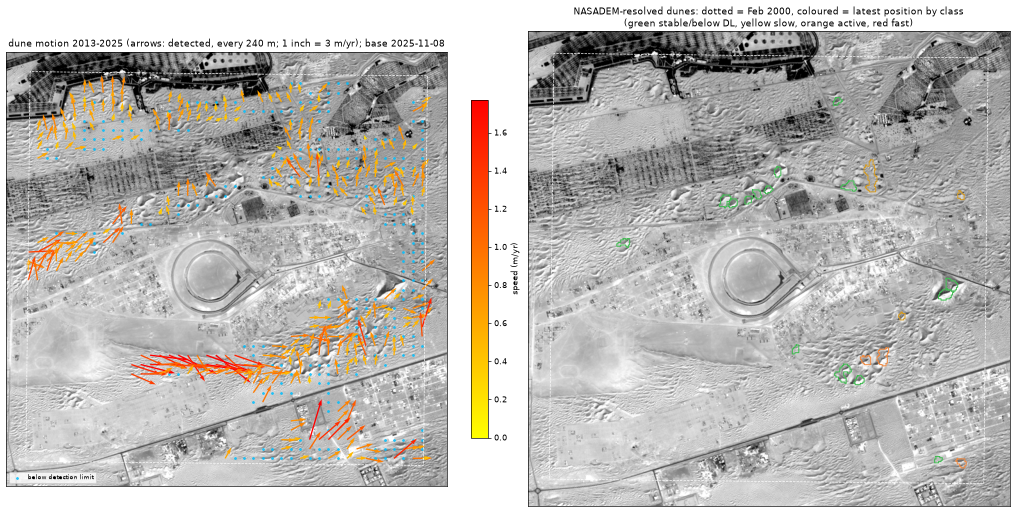

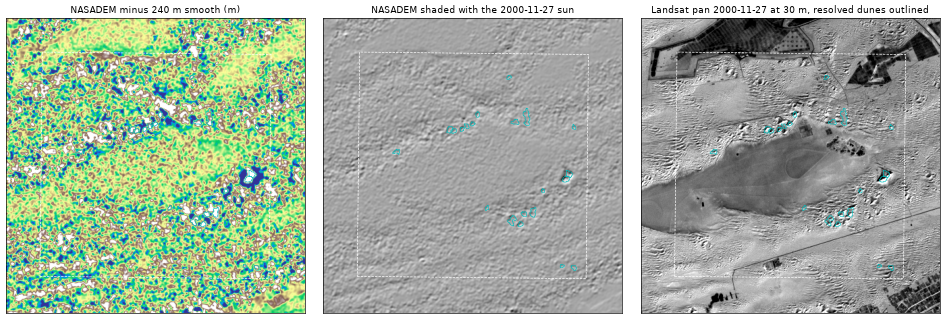

In [20]:
# WHAT THIS DOES: writes vectors.geojson (detected windows only, thinned to every 2nd window = 240 m) and draws the
# velocity field and the dune outlines over the latest image.
ri, ci = np.unravel_index(DUNE_IDX, NWX)
thin = (ri % P["vector_thin"] == 0) & (ci % P["vector_thin"] == 0)
vsel = DET & thin
lon_, lat_ = to_ll(xw[vsel], yw[vsel])
vfeat = []
for k_, (lo_, la_) in enumerate(zip(lon_, lat_)):
    w_ = np.where(vsel)[0][k_]
    vfeat.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(float(lo_), 6), round(float(la_), 6)]},
                  "properties": {"speed_myr": round(float(SPEED[w_]), 2), "heading_deg": round(float(HEAD[w_]), 1), "quality": round(float(QUAL[w_]), 2),
                                 "uncertainty_myr": round(float(SIG[w_]), 2), "detection_limit_myr": round(float(DL_W[w_]), 2),
                                 "east_myr": round(float(VEL["vE"][w_]), 3), "north_myr": round(float(VEL["vN"][w_]), 3)}})
vnote = (f"Dune-motion vectors, Landsat 8/9 OLI pan (15 m), November scenes {SC.date[OLI[0]]} to {SC.date[OLI[-1]]}, 480 m windows; one point per 240 m, "
         f"ONLY where motion is detected (speed > 2.45 x calibrated sigma; median detection limit {DL_FIELD:.2f} m/yr). Areas without points: motion below the "
         "detection limit, masked non-dune surface, or outside the box. heading_deg = direction of motion (0 = N, clockwise). quality = median phase-correlation peak "
         "x share of pairs used (0-1). Computed by pipeline/02_tracking_and_dunes.ipynb.")
(PUB / "vectors.geojson").write_text(json.dumps({"type": "FeatureCollection", "note": vnote, "features": vfeat}, separators=(",", ":")) + "\n")
print(f"wrote {len(vfeat)} vectors -> {(PUB / 'vectors.geojson').relative_to(config.ROOT)}")

fig, axes = plt.subplots(1, 2, figsize=(17, 8.4))
for a in axes:
    a.imshow(base, cmap="gray", extent=extent(GRID)); box_outline(a)
    a.set_xlim(GRID.x0 + 1000, GRID.x0 + GRID.width * RES - 1000); a.set_ylim(GRID.y0 - GRID.height * RES + 1000, GRID.y0 - 1000); a.set_xticks([]); a.set_yticks([])
a = axes[0]
bd = d_valid & ~DET
a.scatter(xw[bd & thin], yw[bd & thin], s=5, c="deepskyblue", alpha=0.8, label="below detection limit")
q = a.quiver(xw[vsel], yw[vsel], VEL["vE"][vsel], VEL["vN"][vsel], SPEED[vsel], cmap="autumn_r", scale=3, scale_units="inches", width=0.003, clim=(0, np.percentile(SPEED[DET], 98)))
plt.colorbar(q, ax=a, fraction=0.035, label="speed (m/yr)")
a.set_title(f"dune motion {SC.date[OLI[0]][:4]}-{SC.date[OLI[-1]][:4]} (arrows: detected, every 240 m; 1 inch = 3 m/yr); base {SC.date[LATEST]}")
a.legend(loc="lower left", fontsize=7)
a = axes[1]
for f0, f1 in zip(feats0, feats):
    x0_, y0_ = np.array(Transformer.from_crs("EPSG:4326", GRID.crs, always_xy=True).transform(*np.array(f0["geometry"]["coordinates"][0]).T))
    x1_, y1_ = np.array(Transformer.from_crs("EPSG:4326", GRID.crs, always_xy=True).transform(*np.array(f1["geometry"]["coordinates"][0]).T))
    col = {"stable": "#3fb950", "slow": "#d29922", "active": "#f0883e", "fast": "#f85149"}[f1["properties"]["class"]]
    a.plot(x0_, y0_, color="white", lw=0.6, ls=":"); a.plot(x1_, y1_, color=col, lw=1.2)
a.set_title("NASADEM-resolved dunes: dotted = Feb 2000, coloured = latest position by class\n(green stable/below DL, yellow slow, orange active, red fast)")
plt.tight_layout(); plt.savefig(OUT / "02_velocity_field_and_dunes.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
ext30 = extent(G30)
axes[0].imshow(dn.highpass(z_s, 8), cmap="terrain", vmin=-8, vmax=8, extent=ext30); axes[0].set_title("NASADEM minus 240 m smooth (m)")
axes[1].imshow(shade, cmap="gray", extent=ext30); axes[1].set_title(f"NASADEM shaded with the {SC.date[E0]} sun")
axes[2].imshow(stretch(p30), cmap="gray", extent=ext30); axes[2].set_title(f"Landsat pan {SC.date[E0]} at 30 m, resolved dunes outlined")
for f0 in feats0:
    x0_, y0_ = np.array(Transformer.from_crs("EPSG:4326", GRID.crs, always_xy=True).transform(*np.array(f0["geometry"]["coordinates"][0]).T))
    for a in axes: a.plot(x0_, y0_, "c-", lw=0.7)
for a in axes: a.set_xticks([]); a.set_yticks([]); box_outline(a)
plt.tight_layout(); plt.savefig(OUT / "02_nasadem_test.png"); plt.show()

In [21]:
# WHAT THIS DOES: writes the full per-window velocity field (every dune window on the 120 m grid, detected or not, with its
# calibrated uncertainty and detection flag) to pipeline/outputs/<site>/02_velocity_field.csv. Notebook 03 builds the threat
# analysis and the advection field from this table; vectors.geojson above is only a thinned, detected-only display copy.
xw_all, yw_all = GRID.xy(rr[DUNE_IDX], cc[DUNE_IDX])
lon_all, lat_all = to_ll(xw_all, yw_all)
VF = pd.DataFrame({
    "win_row": rr[DUNE_IDX], "win_col": cc[DUNE_IDX], "x_m": xw_all, "y_m": yw_all,
    "lon": np.round(lon_all, 6), "lat": np.round(lat_all, 6),
    "valid": d_valid, "detected": DET,
    "east_myr": VEL["vE"], "north_myr": VEL["vN"], "speed_myr": SPEED, "heading_deg": HEAD,
    "sigma_myr": SIG, "detection_limit_myr": DL_W, "quality": QUAL,
    "nondune_frac": F_ND[DUNE_IDX], "n_pairs_used": VEL["n_used"], "n_epochs": VEL["n_epochs"],
})
VF.loc[~VF.valid, ["east_myr", "north_myr", "speed_myr", "heading_deg"]] = np.nan
VF.round({"x_m": 1, "y_m": 1, "east_myr": 4, "north_myr": 4, "speed_myr": 4, "heading_deg": 2, "sigma_myr": 4,
          "detection_limit_myr": 4, "quality": 3, "nondune_frac": 3}).to_csv(OUT / "02_velocity_field.csv", index=False)
QC["velocity_field_table"] = {"file": f"pipeline/outputs/{SID}/02_velocity_field.csv", "n_windows": int(len(VF)),
                              "window_px": P["win"], "step_px": P["step"], "res_m": RES, "grid": GRID.to_dict(),
                              "columns_note": "x_m/y_m = window centre in the site CRS; sigma_myr = calibrated per-component 1-sigma; "
                                              "detected = speed > detection_limit_myr (= 2.45 sigma); speeds/headings blank where not valid"}
print(f"wrote {len(VF)} dune windows ({int(VF.detected.sum())} detected) -> {(OUT / '02_velocity_field.csv').relative_to(config.ROOT)}")


wrote 2417 dune windows (1394 detected) -> pipeline/outputs/seih_al_hama/02_velocity_field.csv


## 16 · QC summary and site index

In [22]:
# WHAT THIS DOES: writes the machine-readable QC summary, rebuilds public/data/sites.json, checks the §4 fields of the
# written files and the size of public/data, and prints a plain-language summary generated from the numbers.
QC["scenes"] = SC.drop(columns=["ee_asset"]).round(4).to_dict("records")
QC["velocity_summary"] = {
    "period": f"{SC.date[OLI[0]]} to {SC.date[OLI[-1]]}", "n_oli_scenes": len(OLI), "n_oli_pairs": len(PAIRS_OLI),
    "n_windows_grid": int(rr.size), "n_dune_windows": int(DUNE_IDX.size), "n_valid_dune_windows": int(d_valid.sum()),
    "n_detected": int(DET.sum()), "pct_detected_of_valid": round(100 * float(DET.sum() / d_valid.sum()), 1),
    "detected_speed_median_myr": round(float(np.median(SPEED[DET])), 3),
    "detected_speed_p10_p90_myr": [round(float(np.percentile(SPEED[DET], 10)), 3), round(float(np.percentile(SPEED[DET], 90)), 3)],
    "detected_speed_range_myr": [round(float(SPEED[DET].min()), 3), round(float(SPEED[DET].max()), 3)],
    "detected_heading_quartiles_deg": [round(float(x), 1) for x in np.percentile(HEAD[DET], [25, 50, 75])],
    "field_median_heading_deg": round(FIELD_HEAD, 1),
}
QC["dunes"] = {"n_resolved_nasadem": int(len(DD)), "n_exported": len(feats), "counts_by_class": counts,
               "class_cutoffs_myr": {"stable": "below detection limit", "slow": f"< {CUT1:.2f}", "active": f"{CUT1:.2f}-{CUT2:.2f}", "fast": f">= {CUT2:.2f}"},
               "height_model": HEIGHT_MODEL, "n_untracked_resolved": int(len(untracked)),
               "min_resolvable": {"height_m": round(float(DD.height_m.min()), 1) if len(DD) else None,
                                  "area_ha": round(float(DD.area_km2.min() * 100), 1) if len(DD) else None,
                                  "rule": f"crest >= {H_MIN:.1f} m (3 x NASADEM noise) and DEM shading matching the image"},
               "threat_fields": "not computed (notebook 03): threat=false, nearest_target/distance/reach years = null"}
QC["vectors"] = {"n_points": len(vfeat), "spacing_m": P["vector_thin"] * P["step"] * RES, "content": "detected windows only"}
QC["masks"]["n_stable_windows"] = int(STABLE.sum())
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (pd.Timestamp, dt.date)): return str(o)
    return str(o)
def clean_nan(o):
    if isinstance(o, dict): return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, list): return [clean_nan(v) for v in o]
    if isinstance(o, float) and not np.isfinite(o): return None
    return o
(OUT / "02_qc_summary.json").write_text(json.dumps(clean_nan(json.loads(json.dumps(QC, default=jsonable))), indent=1) + "\n")
idx = site_index.write_index()
print("site index:", {s["id"]: (s["status"], s["files"]) for s in idx["sites"] if s["data_dir"]})

# §4 field check
REQ = {"id": str, "height_m": (int, float), "area_km2": (int, float), "speed_med_myr": (int, float), "speed_lo_myr": (int, float), "speed_hi_myr": (int, float),
       "heading_deg": (int, float, type(None)), "uncertainty_myr": (int, float), "confidence": str, "speed_source": str, "class": str, "threat": bool,
       "nearest_target": (str, type(None)), "distance_to_target_m": (int, float, type(None)), "reach_year_min": (int, type(None)), "reach_year_max": (int, type(None)),
       "wind_agreement_deg": (int, float, type(None))}
dj = json.loads((PUB / "dunes.geojson").read_text()); d0 = json.loads((PUB / "dunes_2000.geojson").read_text()); vj = json.loads((PUB / "vectors.geojson").read_text())
for f in dj["features"]:
    pr = f["properties"]
    assert all(k_ in pr and isinstance(pr[k_], t_) for k_, t_ in REQ.items()), pr
    assert pr["confidence"] in ("high", "medium", "low") and pr["speed_source"] in ("tracked", "height_model") and pr["class"] in ("stable", "slow", "active", "fast")
    assert f["geometry"]["type"] == "Polygon"
assert [f["properties"]["id"] for f in dj["features"]] == [f["properties"]["id"] for f in d0["features"]]
for f in vj["features"]:
    pr = f["properties"]; assert f["geometry"]["type"] == "Point" and all(isinstance(pr[k_], (int, float)) for k_ in ("speed_myr", "heading_deg", "quality")) and 0 <= pr["quality"] <= 1
n_null_head = sum(f["properties"]["heading_deg"] is None for f in dj["features"])
size = sum(p_.stat().st_size for p_ in config.PUBLIC_DATA.rglob("*") if p_.is_file())
print(f"§4 check passed: {len(dj['features'])} dunes (heading null for {n_null_head} below-detection-limit dunes), {len(vj['features'])} vectors; public/data total {size / 1e6:.2f} MB")

# plain-language summary generated from the numbers
vs = QC["velocity_summary"]; nd_ = QC["noise_and_detection"]; il = QC["illumination"]; la = QC["linearity_aliasing"]; ph = QC["physics"]
lines = [
    f"Site {SID}: {vs['n_valid_dune_windows']} dune windows (480 m, every 120 m) tracked on {len(OLI)} Landsat 8/9 November scenes {vs['period']}.",
    f"Noise: stable-ground residual per image pair NMAD {QC['stable_ground_pairwise']['nmad_E_m']:.2f} m (E) / {QC['stable_ground_pairwise']['nmad_N_m']:.2f} m (N); "
    f"held-out stable ground 'moves' at {nd_['held_out_stable_speed_median_myr']:.2f} m/yr median, {nd_['held_out_stable_speed_p95_myr']:.2f} m/yr at the 95th percentile.",
    f"Detection limit (95 %): median {nd_['detection_limit_median_myr']:.2f} m/yr per window (5-95 %: {nd_['detection_limit_p5_p95_myr'][0]:.2f}-{nd_['detection_limit_p5_p95_myr'][1]:.2f}).",
    f"Motion detected in {vs['n_detected']} windows ({vs['pct_detected_of_valid']:.0f} %); their speeds: median {vs['detected_speed_median_myr']:.2f}, "
    f"10-90 % {vs['detected_speed_p10_p90_myr'][0]:.2f}-{vs['detected_speed_p10_p90_myr'][1]:.2f}, max {vs['detected_speed_range_myr'][1]:.2f} m/yr; field heading {vs['field_median_heading_deg']:.0f} deg.",
    f"Linearity: along-motion displacement grows {la['along_motion_slope_myr']:.2f} m/yr x dt (intercept {la['along_motion_intercept_m']:+.2f} m); short vs long baselines r = "
    f"{la['corr_short_vs_long_E_N'][0]:.2f}/{la['corr_short_vs_long_E_N'][1]:.2f}; largest 12-yr displacement {la['p99_speed_times_baseline_m']:.0f} m vs dune spacing "
    f"{la['dune_spacing_25pct_variance_below_m']}-{la['dune_spacing_spectral_peak_m']} m: no room for aliasing.",
    f"Illumination: {il['field_slope_m_per_deg_E_N'][0]:+.3f} (E) / {il['field_slope_m_per_deg_E_N'][1]:+.3f} (N) m per degree of sun elevation; effect on velocity "
    f"{il['velocity_bias_field_myr']:.3f} m/yr (field), {il['velocity_bias_per_window_p95_myr']:.3f} m/yr (95th pct window).",
    f"Wind: field heading differs from RDD {ph['wind_RDD_deg']:.0f} deg by {ph['field_heading_minus_RDD_deg']:.0f} deg; from the two sand-moving modes "
    f"({ph['wind_mode_toward_deg'][0]:.0f}, {ph['wind_mode_toward_deg'][1]:.0f} deg) by {ph['field_heading_minus_modes_deg'][0]:.0f} and {ph['field_heading_minus_modes_deg'][1]:.0f} deg.",
]
iv_ = QC["interannual"]
lines.append(f"Year to year: illumination-corrected field-median interval velocities {iv_['dune_interval_median_range_myr_illum_corrected'][0]:.2f} to "
             f"{iv_['dune_interval_median_range_myr_illum_corrected'][1]:.2f} m/yr; " + ("above" if iv_["above_noise"] else "NOT above") +
             f" the dune-specific noise (p = {iv_['p_value_vs_dune_noise']:.3f}); correlation with MERRA-2 drift r = {iv_['wind_correlation']['pearson_r']:.2f} (p = {iv_['wind_correlation']['pearson_p']:.2f}).")
if QC.get("landsat7_long_baseline"):
    l7_ = QC["landsat7_long_baseline"]
    lines.append(f"Landsat 7 long baseline: 2000 position available for {l7_['windows_with_2000_position']} windows; 2000-2025 vs 2013-2025 velocity r = "
                 f"{l7_['corr_2000_2025_vs_2013_2025_E_N'][0]:.2f}/{l7_['corr_2000_2025_vs_2013_2025_E_N'][1]:.2f}, median speed {l7_['median_speed_2000_2025_detected_myr']:.2f} vs "
                 f"{l7_['median_speed_2013_2025_same_windows_myr']:.2f} m/yr.")
for p_, H in HLS.items():
    c_ = H["cmp"]
    lines.append(f"{p_} ({c_['years']}): r = {c_['corr_E']:.2f} (E), {c_['corr_N']:.2f} (N) against Landsat over the same years; field speed {c_['field_median_speed_hls_myr']:.2f} vs "
                 f"{c_['field_median_speed_landsat_myr']:.2f} m/yr, headings differ by {c_['heading_difference_deg']:.0f} deg; its own detection limit {c_['hls_detection_limit_median_myr']:.2f} m/yr.")
lines.append(f"NASADEM: noise {QC['nasadem']['noise_sigma_m']:.1f} m; {QC['nasadem']['n_resolved']} of {QC['nasadem']['n_candidates']} crest candidates resolved; "
             f"{len(feats)} dunes exported, classes {counts}.")
print("\n".join(lines))

site index: {'seih_al_hama': ('partial', {'summary.json': 'placeholder', 'dunes.geojson': 'real', 'dunes_2000.geojson': 'real', 'vectors.geojson': 'real', 'targets.geojson': 'placeholder', 'wind_summary.json': 'real', 'sources.json': 'placeholder', 'frames/manifest.json': 'placeholder'}), 'sweihan': ('partial', {'summary.json': 'placeholder', 'dunes.geojson': 'placeholder', 'dunes_2000.geojson': 'placeholder', 'vectors.geojson': 'placeholder', 'targets.geojson': 'placeholder', 'wind_summary.json': 'real', 'sources.json': 'placeholder', 'frames/manifest.json': 'placeholder'}), 'liwa': ('partial', {'summary.json': 'placeholder', 'dunes.geojson': 'placeholder', 'dunes_2000.geojson': 'placeholder', 'vectors.geojson': 'placeholder', 'targets.geojson': 'placeholder', 'wind_summary.json': 'real', 'sources.json': 'placeholder', 'frames/manifest.json': 'placeholder'})}
§4 check passed: 21 dunes (heading null for 15 below-detection-limit dunes), 337 vectors; public/data total 0.45 MB
Site seih_a

## Limits (read with the printed summary above)

- **What a velocity here is.** The displacement of the sand surface pattern inside a 480 m window between November scenes, 2013 to the latest scene, after removing each image's offset measured on stable ground. In a field of small dunes this is the migration of those dunes and of the sand sheets around them. It is not the migration of an individual large dune body, and the windows do not resolve single dunes smaller than ~480 m.
- **Detection limit.** Calibrated so that 5 % of stable-ground windows would be called "moving". Stable ground here is mostly farms and older built-up areas, which change a little themselves, so the limit is conservative. Below it, nothing is claimed except "slower than the limit".
- **Errors that only dunes have.** Shading, haze and the look of the sand differ between dates in ways stable ground does not show. The illumination-test pairs (weeks apart) measure this directly for the field median; it sets how far year-to-year changes can be trusted.
- **Masks are partly by hand.** Areas of obvious human change missed by NDVI, WorldCover and OpenStreetMap are excluded with drawn polygons (each with its reason, in `site_config/<site>/manual_masks.geojson`). Unmapped smaller changes (a new fence, a track) can still affect individual windows; masked pixels inside dune windows are given zero weight.
- **Second dataset.** HLS L30 is the same Landsat instruments and is not independent. HLS S30 (Sentinel-2) is, but at 30 m its detection limit is coarser; its agreement is reported as measured, including where it disagrees.
- **Wind.** MERRA-2 is a ~50 km reanalysis of hourly means, so its drift direction is a regional estimate; with a bimodal regime the resultant direction is a small difference of two large vectors and is sensitive to that coarseness.
- **NASADEM** is from February 2000 with metre-level noise. Only dunes whose DEM relief reproduces the image shading are outlined, so the outlines cover the larger dunes only and heights are given only for them.
- **Threats** (roads, farms, reach years) are not computed here; they belong to notebook 03.